# Resiliência Criativa sob Vulnerabilidade Socioeconômica no PISA 2022 (Google Colab)

**Autor:** José Edson Sebastião (`joseedson.sebastiao@ufrpe.br`)  
**Orientador:** Prof. Dr. Rodrigo Lins Rodrigues (PPGIA/UFRPE)  
**Disciplina:** Mineração de Dados Educacionais — Prof. Dr. Rafael Ferreira Leite de Mello  

Este notebook reproduz integralmente o pipeline estatístico e de aprendizado de máquina do artigo **"Resiliência Criativa sob Vulnerabilidade Socioeconômica: Preditores, Equidade de Subgrupos e Transportabilidade Transnacional no PISA 2022"**.

### Como executar no Google Colab
1. Verifique se o runtime está em **R** (`Ambiente de execução` $\rightarrow$ `Alterar o tipo de ambiente de execução` $\rightarrow$ **R**). O arquivo já está configurado com kernel `ir`.
2. Na barra lateral esquerda (**Arquivos** $\rightarrow$ `/content/`), faça o upload do arquivo **`dados_pisa_colab.zip`** (~15 MB) — ou dos 3 arquivos da pasta `data/` (`CY08MSP_STU_QQQ_BRASIL.csv`, `PISA2022_BRASIL_ANALYSIS.csv` e `pisa2022_multicountry.rds`).
3. Clique em **`Ambiente de execução` $\rightarrow$ `Executar tudo`**.  
   *Tempo estimado no Colab: ~30–60s para instalação binária dos pacotes na Célula 1 e ~2–4 minutos para o pipeline completo nos 10 Plausible Values.*

## Etapa 1 — Ambiente, Instalação Rápida de Pacotes e Localização dos Dados

Detecta automaticamente se o ambiente é Google Colab/Linux (instalando binários pré-compilados via `apt-get` + Posit Package Manager como alternativa para evitar compilação C++ lenta), localiza os dados ou descompacta `dados_pisa_colab.zip`, carrega os pacotes e cria `results/` e `figures/`.

In [1]:
# ============================================================================
# CÉLULA 1: AMBIENTE, PACOTES E DADOS (COMPATÍVEL COM GOOGLE COLAB E LOCAL)
# ============================================================================
pacotes <- c(
  "data.table", "haven", "dplyr", "tidyr", "ranger", "pROC",
  "survey", "mitools", "rpart", "xgboost", "ggplot2", "Hmisc"
)

instalados <- rownames(installed.packages())
faltantes <- setdiff(pacotes, instalados)

eh_linux <- identical(Sys.info()[["sysname"]], "Linux")
eh_colab <- eh_linux && (
  dir.exists("/content") ||
  nzchar(Sys.getenv("COLAB_RELEASE_TAG")) ||
  nzchar(Sys.getenv("COLAB_GPU"))
)

if (length(faltantes) > 0) {
  cat("Instalando pacotes faltantes:", paste(faltantes, collapse = ", "), "\n")
  if (eh_linux && file.exists("/etc/debian_version")) {
    mapa_apt <- c(
      data.table = "r-cran-data.table",
      haven      = "r-cran-haven",
      dplyr      = "r-cran-dplyr",
      tidyr      = "r-cran-tidyr",
      ranger     = "r-cran-ranger",
      pROC       = "r-cran-proc",
      survey     = "r-cran-survey",
      mitools    = "r-cran-mitools",
      rpart      = "r-cran-rpart",
      xgboost    = "r-cran-xgboost",
      ggplot2    = "r-cran-ggplot2",
      Hmisc      = "r-cran-hmisc"
    )
    apt_cand <- unname(mapa_apt[faltantes])
    apt_cand <- apt_cand[!is.na(apt_cand)]
    if (length(apt_cand) > 0 && identical(system("id -u", intern = TRUE), "0")) {
      system("apt-get update -qq", ignore.stdout = TRUE, ignore.stderr = TRUE)
      apt_ok <- sapply(apt_cand, function(p) {
        system(paste("apt-cache show", p, ">/dev/null 2>&1")) == 0
      })
      if (any(apt_ok)) {
        cat("  -> Via apt-get (binários Ubuntu):", paste(apt_cand[apt_ok], collapse = " "), "\n")
        system(paste("DEBIAN_FRONTEND=noninteractive apt-get install -y -qq",
                     paste(apt_cand[apt_ok], collapse = " ")))
      }
    }
    faltantes <- setdiff(pacotes, rownames(installed.packages()))
    if (length(faltantes) > 0) {
      codename <- tryCatch(trimws(system("lsb_release -cs", intern = TRUE)), error = function(e) "jammy")
      if (!nzchar(codename)) codename <- "jammy"
      options(HTTPUserAgent = sprintf(
        "R/%s R (%s)", getRversion(),
        paste(getRversion(), R.version$platform, R.version$arch, R.version$os)
      ))
      ppm_url <- sprintf("https://packagemanager.posit.co/cran/__linux__/%s/latest", codename)
      cat("  -> Restantes via Posit Package Manager / CRAN:", paste(faltantes, collapse = ", "), "\n")
      install.packages(faltantes, repos = c(PPM = ppm_url, CRAN = "https://cloud.r-project.org"))
    }
  } else {
    install.packages(faltantes, repos = "https://cloud.r-project.org")
  }
}

suppressPackageStartupMessages({
  for (p in pacotes) library(p, character.only = TRUE)
})

set.seed(2024)
dir.create("results", recursive = TRUE, showWarnings = FALSE)
dir.create("figures", recursive = TRUE, showWarnings = FALSE)

# Helper para exibir figuras PNG inline apenas quando em kernel Jupyter/Colab
exibir_png <- function(caminho_png) {
  em_notebook <- ("IRkernel" %in% loadedNamespaces()) ||
                 nzchar(Sys.getenv("JPY_PARENT_PID")) ||
                 eh_colab
  if (em_notebook && requireNamespace("IRdisplay", quietly = TRUE) && file.exists(caminho_png)) {
    IRdisplay::display_png(file = caminho_png)
  }
}

# Localizar ou descompactar dados do PISA 2022
arqs_br <- c("CY08MSP_STU_QQQ_BRASIL.csv", "PISA2022_BRASIL_ANALYSIS.csv")
pastas_busca <- unique(c("data", ".", "/content/data", "/content"))

achar_pasta_dados <- function() {
  for (d in pastas_busca) {
    if (all(file.exists(file.path(d, arqs_br)))) return(d)
  }
  return(NULL)
}

CAMINHO_DADOS <- achar_pasta_dados()
if (is.null(CAMINHO_DADOS)) {
  zips <- file.path(unique(c(".", "/content")), "dados_pisa_colab.zip")
  zips <- zips[file.exists(zips)]
  if (length(zips) > 0) {
    cat("Descompactando:", zips[1], "...\n")
    unzip(zips[1], exdir = ".")
    CAMINHO_DADOS <- achar_pasta_dados()
  }
}

if (is.null(CAMINHO_DADOS)) {
  stop(
    "Arquivos de dados não encontrados.\n",
    "No Google Colab: clique no ícone de pasta ('Arquivos') na barra esquerda e envie ",
    "'dados_pisa_colab.zip' (ou os arquivos de 'data/') para '/content/', depois execute esta célula novamente."
  )
}

cat("[OK] Ambiente pronto (R", as.character(getRversion()), ")\n")
cat("[OK] Diretório de dados:", normalizePath(CAMINHO_DADOS), "\n")
cat("[OK] Arquivo multicountry presente:",
    file.exists(file.path(CAMINHO_DADOS, "pisa2022_multicountry.rds")), "\n")

Descompactando: ./dados_pisa_colab.zip ...
[OK] Ambiente pronto (R 4.6.0 )
[OK] Diretório de dados: /private/tmp/colab_validation_run/data 
[OK] Arquivo multicountry presente: TRUE 

## Etapa 2 — Carregamento e Vinculação dos Microdados do Brasil

Carrega `CY08MSP_STU_QQQ_BRASIL.csv` e `PISA2022_BRASIL_ANALYSIS.csv` (10 valores plausíveis de pensamento criativo `PV1CRTH_NC` a `PV10CRTH_NC`) e realiza o vínculo determinístico por `CNTSTUID`.

In [2]:
# ============================================================================
# CÉLULA 2: CARREGAMENTO E VINCULAÇÃO DOS DADOS (BRASIL, N = 10.798)
# ============================================================================
carregar_base <- function(caminho, nome_base) {
  arq_csv <- file.path(caminho, paste0(nome_base, ".csv"))
  arq_sav <- file.path(caminho, paste0(nome_base, ".sav"))
  if (file.exists(arq_csv)) {
    cat("Lendo arquivo CSV:", arq_csv, "\n")
    return(data.table::fread(arq_csv))
  } else if (file.exists(arq_sav)) {
    cat("Lendo arquivo SAV (SPSS):", arq_sav, "\n")
    return(data.table::as.data.table(haven::read_sav(arq_sav)))
  } else {
    stop("Arquivo não encontrado (nem .csv nem .sav): ", nome_base)
  }
}

qqq <- carregar_base(CAMINHO_DADOS, "CY08MSP_STU_QQQ_BRASIL")
ana <- carregar_base(CAMINHO_DADOS, "PISA2022_BRASIL_ANALYSIS")

pv_cols <- paste0("PV", 1:10, "CRTH_NC")
dados <- merge(qqq, ana[, c("CNTSTUID", pv_cols), with = FALSE], by = "CNTSTUID")

cat("=== PISA 2022 Brasil ===\n")
cat("Total de estudantes:", nrow(dados), "\n")
cat("Escolas:", length(unique(dados$CNTSCHID)), "\n")

Lendo arquivo CSV: data/CY08MSP_STU_QQQ_BRASIL.csv 
Lendo arquivo CSV: data/PISA2022_BRASIL_ANALYSIS.csv 
=== PISA 2022 Brasil ===
Total de estudantes: 10798 
Escolas: 598 

## Etapa 3 — População Vulnerável e Quatro Definições Operacionais de Resiliência Criativa

Delimita os estudantes brasileiros socioeconomicamente vulneráveis ($\text{ESCS} \le Q_1$ ponderado) e confronta:
- **População Total:** proporção incondicional ($\text{ESCS} \le Q_1 \cap \text{PV}_m \ge Q_3$) sobre $N = 10.798$;
- **Definição A (Principal):** quartil superior nacional ($\text{PV}_m \ge Q_3$) entre vulneráveis;
- **Definição B (Residual Nacional):** resíduo positivo da regressão linear nacional $\text{PV}_m \sim \text{ESCS}$ ($\hat{\varepsilon}_{im} > 0$);
- **Definição C (Contínua):** resíduo padronizado médio pelo desvio-padrão residual nacional;
- **Definição Internacional (Nível 3 OCDE):** pontuação $\text{PV}_m \ge 32,0$ entre vulneráveis.

In [3]:
# ============================================================================
# CÉLULA 3: DEFINIÇÕES OPERACIONAIS DE RESILIÊNCIA CRIATIVA (10 PVs)
# ============================================================================
q1_escs <- wtd.quantile(dados$ESCS, dados$W_FSTUWT, 0.25, na.rm = TRUE)
q3_ct <- sapply(pv_cols, function(p) wtd.quantile(dados[[p]], dados$W_FSTUWT, 0.75, na.rm = TRUE))

dados$vulneravel <- ifelse(!is.na(dados$ESCS) & dados$ESCS <= q1_escs, 1L, 0L)

# Definição A: ESCS <= Q1 e PV >= Q3 nacional
for (i in 1:10) {
  dados[[paste0("rc_a_pv", i)]] <- ifelse(
    dados$vulneravel == 1 & dados[[pv_cols[i]]] >= q3_ct[i], 1L, 0L
  )
}

# Definição B (Residual nacional > 0), Definição C (Contínua) e Nível 3 OCDE (>= 32 pts)
for (i in 1:10) {
  df_reg_nac <- dados[!is.na(dados[[pv_cols[i]]]) & !is.na(dados$ESCS), ]
  fit_nac <- lm(df_reg_nac[[pv_cols[i]]] ~ df_reg_nac$ESCS, weights = df_reg_nac$W_FSTUWT)
  dp_res_nac <- sqrt(weighted.mean(residuals(fit_nac)^2, df_reg_nac$W_FSTUWT))

  df_vuln_i <- dados[dados$vulneravel == 1 & !is.na(dados[[pv_cols[i]]]) & !is.na(dados$ESCS), ]
  pred_ct <- as.numeric(coef(fit_nac)[1] + coef(fit_nac)[2] * df_vuln_i$ESCS)
  residuos <- df_vuln_i[[pv_cols[i]]] - pred_ct

  dados[[paste0("rc_b_pv", i)]] <- NA_integer_
  dados[[paste0("rc_b_pv", i)]][match(df_vuln_i$CNTSTUID, dados$CNTSTUID)] <- ifelse(residuos > 0, 1L, 0L)

  dados[[paste0("residuo_pv", i)]] <- NA_real_
  dados[[paste0("residuo_pv", i)]][match(df_vuln_i$CNTSTUID, dados$CNTSTUID)] <- residuos / dp_res_nac

  dados[[paste0("rc_niv3_pv", i)]] <- ifelse(
    dados$vulneravel == 1 & dados[[pv_cols[i]]] >= 32.0, 1L, 0L
  )
}

dados_escs_val <- dados[!is.na(dados$ESCS), ]
dados_vuln <- dados[dados$vulneravel == 1 & !is.na(dados$rc_a_pv1), ]
cat("Q1 pond. ESCS:", round(as.numeric(q1_escs), 4), "\n")
cat("Amostra analítica (vulneráveis):", nrow(dados_vuln), "| Escolas:", length(unique(dados_vuln$CNTSCHID)), "\n")

prev_a <- sapply(1:10, function(i) weighted.mean(dados_vuln[[paste0("rc_a_pv", i)]], dados_vuln$W_FSTUWT, na.rm = TRUE))
prev_b <- sapply(1:10, function(i) weighted.mean(dados_vuln[[paste0("rc_b_pv", i)]], dados_vuln$W_FSTUWT, na.rm = TRUE))
prev_niv3 <- sapply(1:10, function(i) weighted.mean(dados_vuln[[paste0("rc_niv3_pv", i)]], dados_vuln$W_FSTUWT, na.rm = TRUE))
prev_pop_total <- sapply(1:10, function(i) weighted.mean(dados[[paste0("rc_a_pv", i)]], dados$W_FSTUWT, na.rm = TRUE))
resid_medio <- sapply(1:10, function(i) weighted.mean(dados_vuln[[paste0("residuo_pv", i)]], dados_vuln$W_FSTUWT, na.rm = TRUE))

df_definicoes <- data.frame(
  PV = as.character(1:10),
  Prev_Pop_Total = round(prev_pop_total * 100, 2),
  Prev_A_Q1xQ3 = round(prev_a * 100, 1),
  Prev_B_Residual = round(prev_b * 100, 1),
  Prev_Niv3_OCDE = round(prev_niv3 * 100, 1),
  Residuo_Medio_Padronizado = round(resid_medio, 3),
  N_Positivos_A = sapply(1:10, function(i) sum(dados_vuln[[paste0("rc_a_pv", i)]] == 1, na.rm = TRUE)),
  N_Positivos_B = sapply(1:10, function(i) sum(dados_vuln[[paste0("rc_b_pv", i)]] == 1, na.rm = TRUE)),
  N_Positivos_Niv3 = sapply(1:10, function(i) sum(dados_vuln[[paste0("rc_niv3_pv", i)]] == 1, na.rm = TRUE)),
  stringsAsFactors = FALSE
)
df_definicoes <- rbind(df_definicoes, data.frame(
  PV = "Consolidado",
  Prev_Pop_Total = round(mean(prev_pop_total) * 100, 2),
  Prev_A_Q1xQ3 = round(mean(prev_a) * 100, 1),
  Prev_B_Residual = round(mean(prev_b) * 100, 1),
  Prev_Niv3_OCDE = round(mean(prev_niv3) * 100, 1),
  Residuo_Medio_Padronizado = round(mean(resid_medio), 3),
  N_Positivos_A = round(mean(df_definicoes$N_Positivos_A)),
  N_Positivos_B = round(mean(df_definicoes$N_Positivos_B)),
  N_Positivos_Niv3 = round(mean(df_definicoes$N_Positivos_Niv3)),
  stringsAsFactors = FALSE
))

fwrite(df_definicoes, "results/definicoes_resiliencia.csv")
print(df_definicoes, row.names = FALSE)

Q1 pond. ESCS: -1.7503 
Amostra analítica (vulneráveis): 2530 | Escolas: 504 
          PV Prev_Pop_Total Prev_A_Q1xQ3 Prev_B_Residual Prev_Niv3_OCDE
           1           2.73         11.4            45.6           11.7
           2           2.98         12.5            45.7           12.2
           3           2.87         12.0            45.8           11.6
           4           2.97         12.4            47.7           11.4
           5           3.07         12.8            45.5           13.1
           6           2.59         10.8            45.0           10.8
           7           2.81         11.7            46.4           11.2
           8           2.75         11.5            45.8           11.2
           9           2.95         12.3            46.7           12.2
          10           2.89         12.1            46.2           11.9
 Consolidado           2.86         11.9            46.0           11.7
 Residuo_Medio_Padronizado N_Positivos_A N_Positivos_B N_P

## Etapa 4 — Prevalência Ponderada com Plano Amostral Complexo (BRR/Fay + Regras de Rubin)

Utiliza os 80 pesos replicados de Fay (`W_FSTURWT1` a `W_FSTURWT80`, $\rho = 0,5$) via `survey::svrepdesign` e consolida os 10 valores plausíveis pelas regras de combinação de Rubin.

Prevalência consolidada (Rubin): 11.95% ± EP = 0.98% | IC 95%: [10.03%, 13.86%]

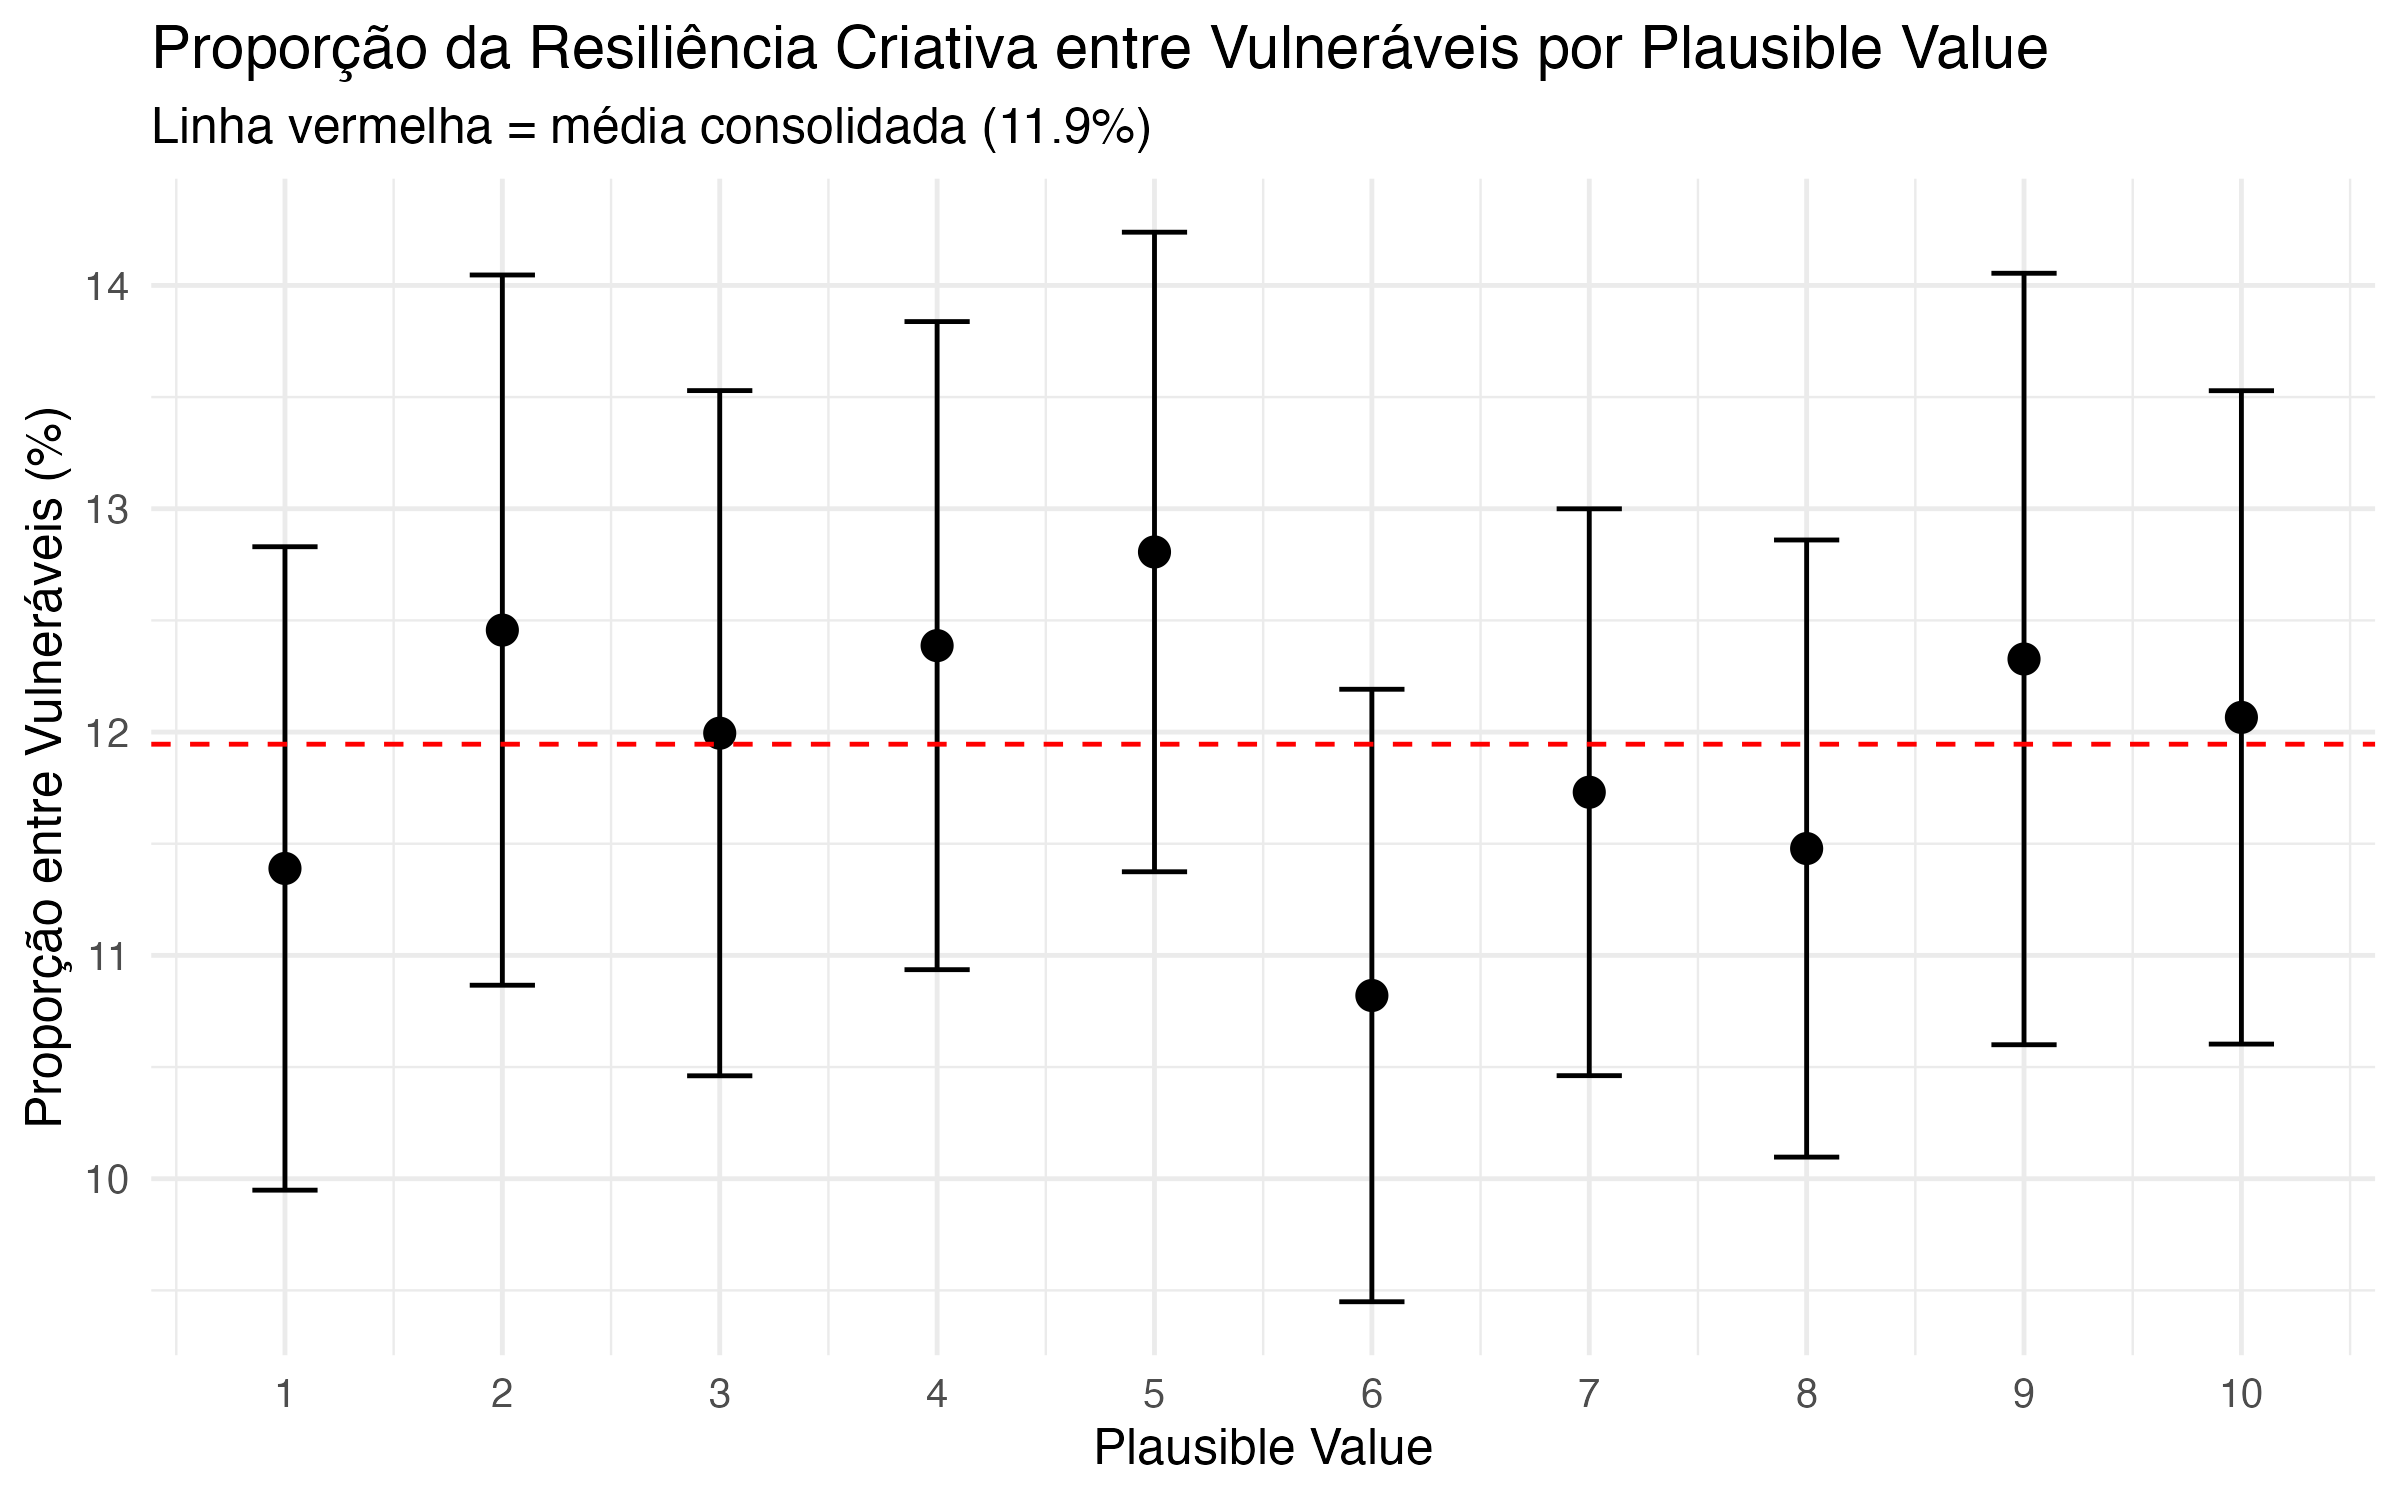

In [4]:
# ============================================================================
# CÉLULA 4: PREVALÊNCIA PONDERADA (BRR / FAY + REGRAS DE RUBIN)
# ============================================================================
rw_names <- paste0("W_FSTURWT", 1:80)
svy_design <- svrepdesign(
  data = dados_vuln, weights = ~W_FSTUWT,
  repweights = dados_vuln[, rw_names, with = FALSE],
  type = "Fay", rho = 0.5, combined.weights = TRUE
)

prev_detalhada <- lapply(1:10, function(i) {
  fmla <- as.formula(paste0("~rc_a_pv", i))
  est <- svymean(fmla, design = svy_design, na.rm = TRUE)
  ci <- confint(est, level = 0.95)
  data.frame(
    PV = as.character(i),
    Prevalencia = as.numeric(est[1]),
    EP = as.numeric(SE(est)[1]),
    IC_lower = ci[1, 1],
    IC_upper = ci[1, 2],
    N_positivos = sum(dados_vuln[[paste0("rc_a_pv", i)]] == 1, na.rm = TRUE),
    N_total = sum(!is.na(dados_vuln[[paste0("rc_a_pv", i)]])),
    stringsAsFactors = FALSE
  )
})
prev_detalhada <- do.call(rbind, prev_detalhada)

prev_media <- mean(prev_detalhada$Prevalencia)
var_entre <- var(prev_detalhada$Prevalencia)
var_dentro <- mean(prev_detalhada$EP^2)
var_total <- var_dentro + (1 + 1 / 10) * var_entre
ep_consolidado <- sqrt(var_total)

prev_consolidada <- data.frame(
  PV = "Consolidado",
  Prevalencia = prev_media,
  EP = ep_consolidado,
  IC_lower = prev_media - 1.96 * ep_consolidado,
  IC_upper = prev_media + 1.96 * ep_consolidado,
  N_positivos = round(mean(prev_detalhada$N_positivos)),
  N_total = prev_detalhada$N_total[1],
  stringsAsFactors = FALSE
)
prev_completa <- rbind(prev_detalhada, prev_consolidada)
fwrite(prev_completa, "results/prevalencia_detalhada.csv")

cat(sprintf("Prevalência consolidada (Rubin): %.2f%% ± EP = %.2f%% | IC 95%%: [%.2f%%, %.2f%%]\n",
            prev_media * 100, ep_consolidado * 100,
            (prev_media - 1.96 * ep_consolidado) * 100,
            (prev_media + 1.96 * ep_consolidado) * 100))

prev_plot <- prev_detalhada
prev_plot$PV <- as.numeric(prev_plot$PV)
p_prev <- ggplot(prev_plot, aes(x = PV, y = Prevalencia * 100)) +
  geom_point(size = 3) +
  geom_errorbar(aes(ymin = IC_lower * 100, ymax = IC_upper * 100), width = 0.3) +
  geom_hline(yintercept = prev_media * 100, linetype = "dashed", color = "red") +
  scale_x_continuous(breaks = 1:10) +
  labs(title = "Proporção da Resiliência Criativa entre Vulneráveis por Plausible Value",
       subtitle = paste0("Linha vermelha = média consolidada (", round(prev_media * 100, 1), "%)"),
       x = "Plausible Value", y = "Proporção entre Vulneráveis (%)") +
  theme_minimal(base_size = 12)

ggsave("figures/prevalencia_por_pv.png", p_prev, width = 8, height = 5, dpi = 300)
exibir_png("figures/prevalencia_por_pv.png")

## Etapa 5 — Seleção dos 24 Preditores, Auditoria de Dados Ausentes e Colinearidade

Retém os 24 preditores demográficos, familiares, tecnológicos e socioemocionais com $\le 50\%$ de ausência na subamostra vulnerável ($n = 2.530$), registra a auditoria de *missingness* e calcula a matriz de correlação de postos de Spearman.

Preditores retidos: 24 | Sem ESCS: 21 | Sem ESCS/TIC domiciliar: 19 
  Variavel N_Validos N_Missing Pct_Missing Metodo_Imputacao
 ST004D01T      2530         0        0.00    Moda (treino)
       AGE      2530         0        0.00 Mediana (treino)
     GRADE      2527         3        0.12 Mediana (treino)
   HOMEPOS      2527         3        0.12 Mediana (treino)
     HISEI      2119       411       16.25 Mediana (treino)
  PAREDINT      2500        30        1.19 Mediana (treino)
    ICTRES      2474        56        2.21 Mediana (treino)
   ICTHOME      1659       871       34.43 Mediana (treino)
    ICTSCH      1789       741       29.29 Mediana (treino)
  ICTAVHOM      1747       783       30.95 Mediana (treino)
  ICTAVSCH      2031       499       19.72 Mediana (treino)
  ICTEFFIC      1310      1220       48.22 Mediana (treino)
null device 
          1 

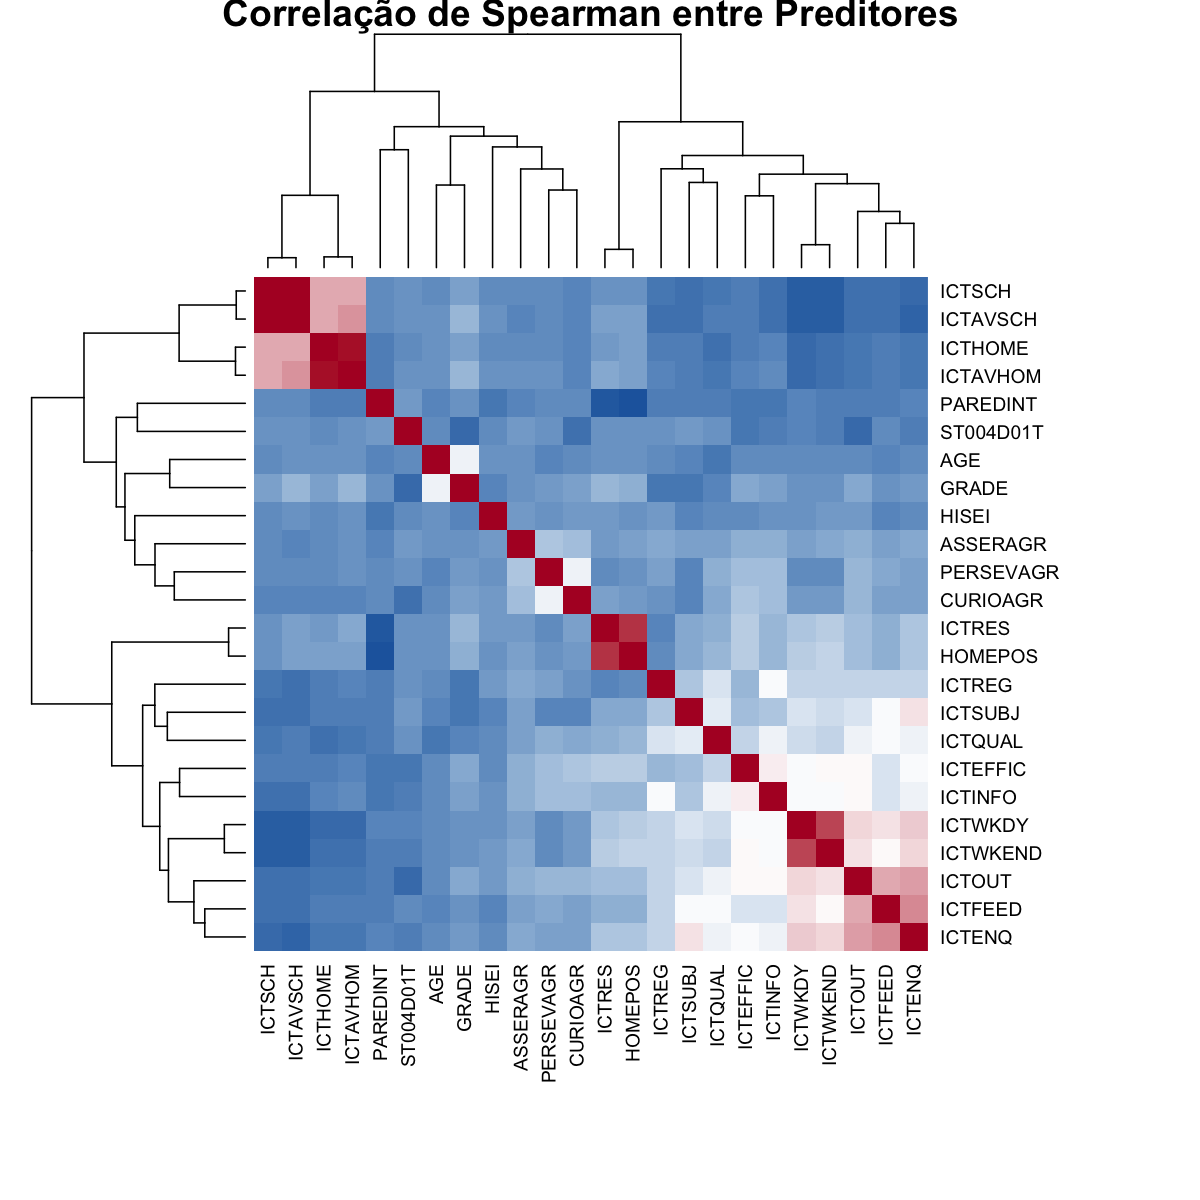

In [5]:
# ============================================================================
# CÉLULA 5: SELEÇÃO DE 24 PREDITORES, MISSING E CORRELAÇÃO DE SPEARMAN
# ============================================================================
preditores_todos <- c(
  "ST004D01T", "AGE", "GRADE", "HOMEPOS", "HISEI", "PAREDINT",
  "ICTRES", "ICTHOME", "ICTSCH", "ICTAVHOM", "ICTAVSCH", "ICTEFFIC",
  "ICTWKDY", "ICTWKEND", "ICTOUT", "ICTREG", "ICTSUBJ", "ICTENQ",
  "ICTFEED", "ICTINFO", "ICTQUAL", "CURIOAGR", "ASSERAGR", "PERSEVAGR"
)
preditores_todos <- intersect(preditores_todos, names(dados_vuln))
miss_rate <- sapply(preditores_todos, function(v) mean(is.na(dados_vuln[[v]])))
excl <- preditores_todos[miss_rate > 0.50]
if (length(excl) > 0) cat("Excluídos (>50% missing):", paste(excl, collapse = ", "), "\n")

preditores <- preditores_todos[miss_rate <= 0.50]
preditores_sem_escs <- setdiff(preditores, c("HOMEPOS", "HISEI", "PAREDINT"))
preditores_sem_escs_ict <- setdiff(preditores_sem_escs, c("ICTRES", "ICTAVHOM"))

cat("Preditores retidos:", length(preditores),
    "| Sem ESCS:", length(preditores_sem_escs),
    "| Sem ESCS/TIC domiciliar:", length(preditores_sem_escs_ict), "\n")

df_missing <- data.frame(
  Variavel = preditores,
  N_Validos = sapply(preditores, function(v) sum(!is.na(dados_vuln[[v]]))),
  N_Missing = sapply(preditores, function(v) sum(is.na(dados_vuln[[v]]))),
  Pct_Missing = round(sapply(preditores, function(v) mean(is.na(dados_vuln[[v]])) * 100), 2),
  Metodo_Imputacao = sapply(preditores, function(v) {
    ifelse(length(unique(na.omit(dados_vuln[[v]]))) <= 5, "Moda (treino)", "Mediana (treino)")
  }),
  row.names = NULL
)
fwrite(df_missing, "results/missing_por_variavel.csv")
print(head(df_missing, 12), row.names = FALSE)

mat_cor <- cor(dados_vuln[, ..preditores], use = "pairwise.complete.obs", method = "spearman")
fwrite(as.data.frame(mat_cor), "results/correlacao_preditores.csv", row.names = TRUE)

png("figures/correlacao_preditores.png", width = 1200, height = 1200, res = 150)
heatmap(mat_cor, col = colorRampPalette(c("#2166AC", "white", "#B2182B"))(50),
        symm = TRUE, margins = c(10, 10),
        main = "Correlação de Spearman entre Preditores")
dev.off()
exibir_png("figures/correlacao_preditores.png")

## Etapa 6 — Partição Agrupada por Escola e Funções do Pipeline Supervisionado

Divide as $504$ escolas em **70% treino ($352$ escolas; $n = 1.783$)** e **30% teste ($152$ escolas; $n = 747$)** e define as funções de imputação isolada no treino, métricas ponderadas (`ROC-AUC`, `PR-AUC`, `Brier`, `F1`), *cluster bootstrap* por escola e treinamento multi-PV.

In [6]:
# ============================================================================
# CÉLULA 6: PARTIÇÃO POR ESCOLA (70/30) E FUNÇÕES AUXILIARES
# ============================================================================
set.seed(2024)
dados_vuln$rc_majority <- ifelse(
  rowSums(dados_vuln[, paste0("rc_a_pv", 1:10), with = FALSE], na.rm = TRUE) >= 5, 1L, 0L
)

escolas <- unique(dados_vuln$CNTSCHID)
escolas_tr <- sample(escolas, floor(length(escolas) * 0.7))
tr_idx <- which(dados_vuln$CNTSCHID %in% escolas_tr)
te_idx <- setdiff(seq_len(nrow(dados_vuln)), tr_idx)

cat("Escolas no treino:", length(escolas_tr), "| no teste:", length(escolas) - length(escolas_tr), "\n")
cat("Treino:", length(tr_idx), "estudantes | Teste:", length(te_idx), "estudantes\n")
cat("Resilientes (regra maioria 10 PVs) -> Treino:", sum(dados_vuln$rc_majority[tr_idx] == 1),
    "| Teste:", sum(dados_vuln$rc_majority[te_idx] == 1), "\n")

get_mode <- function(v) { uni <- unique(v[!is.na(v)]); uni[which.max(tabulate(match(v, uni)))] }

imputar <- function(df_tr, df_te, vars) {
  for (v in vars) {
    val <- if (length(unique(na.omit(df_tr[[v]]))) <= 5) get_mode(df_tr[[v]]) else median(df_tr[[v]], na.rm = TRUE)
    df_tr[[v]][is.na(df_tr[[v]])] <- val
    df_te[[v]][is.na(df_te[[v]])] <- val
  }
  list(tr = df_tr, te = df_te)
}

calc_pr_auc <- function(prob, real) {
  if (sum(real == 1) == 0) return(NA)
  ord <- order(prob, decreasing = TRUE)
  real_s <- real[ord]
  tp_cum <- cumsum(real_s)
  prec <- tp_cum / seq_along(real_s)
  rec <- tp_cum / sum(real_s)
  n <- length(rec)
  if (n < 2) return(NA)
  sum(diff(rec) * (prec[-1] + prec[-n]) / 2)
}

calc_metricas <- function(prob, real, pesos = NULL, limiar = 0.5) {
  val <- !is.na(prob) & !is.na(real)
  prob <- prob[val]; real <- real[val]
  pesos <- if (!is.null(pesos)) pesos[val] else rep(1, length(real))

  roc_obj <- tryCatch(pROC::roc(real, prob, quiet = TRUE), error = function(e) NULL)
  roc_auc <- if (!is.null(roc_obj)) as.numeric(pROC::auc(roc_obj)) else NA
  pr_auc <- calc_pr_auc(prob, real)
  brier <- weighted.mean((prob - real)^2, pesos)

  pred <- ifelse(prob >= limiar, 1L, 0L)
  tp <- sum(pesos[pred == 1 & real == 1])
  tn <- sum(pesos[pred == 0 & real == 0])
  fp <- sum(pesos[pred == 1 & real == 0])
  fn <- sum(pesos[pred == 0 & real == 1])

  accuracy    <- (tp + tn) / sum(pesos)
  precision   <- ifelse((tp + fp) > 0, tp / (tp + fp), NA)
  recall      <- ifelse((tp + fn) > 0, tp / (tp + fn), NA)
  specificity <- ifelse((tn + fp) > 0, tn / (tn + fp), NA)
  f1 <- ifelse(!is.na(precision) & !is.na(recall) & (precision + recall) > 0,
               2 * precision * recall / (precision + recall), NA)
  bal_acc <- ifelse(!is.na(recall) & !is.na(specificity), (recall + specificity) / 2, NA)

  data.frame(roc_auc = roc_auc, pr_auc = pr_auc, brier = brier, accuracy = accuracy,
             precision = precision, recall = recall, specificity = specificity,
             f1 = f1, balanced_accuracy = bal_acc, threshold = limiar)
}

bootstrap_ci <- function(prob, real, pesos = NULL, n_boot = 500, cluster = NULL) {
  n <- length(prob)
  if (is.null(pesos)) pesos <- rep(1, n)
  boot_roc <- boot_pr <- boot_brier <- numeric(n_boot)
  for (b in 1:n_boot) {
    if (is.null(cluster)) {
      idx <- sample(n, n, replace = TRUE)
    } else {
      esc <- unique(cluster)
      sorteio <- sample(esc, length(esc), replace = TRUE)
      idx <- unlist(lapply(sorteio, function(e) which(cluster == e)))
    }
    boot_roc[b]   <- tryCatch(as.numeric(pROC::auc(pROC::roc(real[idx], prob[idx], quiet = TRUE))), error = function(e) NA)
    boot_pr[b]    <- calc_pr_auc(prob[idx], real[idx])
    boot_brier[b] <- weighted.mean((prob[idx] - real[idx])^2, pesos[idx])
  }
  data.frame(
    roc_auc_lo = quantile(boot_roc, 0.025, na.rm = TRUE),
    roc_auc_hi = quantile(boot_roc, 0.975, na.rm = TRUE),
    pr_auc_lo  = quantile(boot_pr, 0.025, na.rm = TRUE),
    pr_auc_hi  = quantile(boot_pr, 0.975, na.rm = TRUE),
    brier_lo   = quantile(boot_brier, 0.025, na.rm = TRUE),
    brier_hi   = quantile(boot_brier, 0.975, na.rm = TRUE)
  )
}

treinar_modelos <- function(dados_vuln, tr_idx, te_idx, preds, usar_pesos = TRUE, label = "") {
  todos <- list(); modelos_rf <- list(); modelos_xgb <- list(); X_te_global <- NULL
  for (i in 1:10) {
    if (nchar(label) > 0) cat(sprintf("  [%s] PV %d/10\n", label, i)) else cat(sprintf("--- PV %d/10 ---\n", i))
    rc_var <- paste0("rc_a_pv", i)
    df_tr <- as.data.frame(dados_vuln[tr_idx, c(preds, rc_var, "W_FSTUWT"), with = FALSE])
    df_te <- as.data.frame(dados_vuln[te_idx, c(preds, rc_var, "W_FSTUWT"), with = FALSE])
    imp <- imputar(df_tr, df_te, preds)
    df_tr <- imp$tr; df_te <- imp$te

    y_tr <- df_tr[[rc_var]]; y_te <- df_te[[rc_var]]
    w_tr <- if (usar_pesos) df_tr$W_FSTUWT / mean(df_tr$W_FSTUWT) else rep(1, nrow(df_tr))
    w_te <- df_te$W_FSTUWT
    limiar <- weighted.mean(y_tr, w_tr)
    X_tr <- df_tr[, preds]; X_te <- df_te[, preds]
    if (i == 1) X_te_global <- X_te

    rf <- ranger(x = X_tr, y = factor(y_tr, levels = c("0", "1")), num.trees = 500,
                 case.weights = w_tr, probability = TRUE, seed = 2024 + i)
    p_rf <- predict(rf, X_te)$predictions[, "1"]
    m_rf <- calc_metricas(p_rf, y_te, w_te, limiar); m_rf$modelo <- "Random Forest"; m_rf$pv <- i
    modelos_rf[[i]] <- rf

    dtrain <- xgb.DMatrix(as.matrix(X_tr), label = y_tr, weight = w_tr)
    xgb_mod <- xgb.train(params = list(objective = "binary:logistic", max_depth = 6, eta = 0.1),
                         data = dtrain, nrounds = 150, verbose = 0)
    p_xgb <- predict(xgb_mod, xgb.DMatrix(as.matrix(X_te)))
    m_xgb <- calc_metricas(p_xgb, y_te, w_te, limiar); m_xgb$modelo <- "XGBoost"; m_xgb$pv <- i
    modelos_xgb[[i]] <- xgb_mod

    lr <- suppressWarnings(glm(y_tr ~ ., data = X_tr, family = binomial, weights = w_tr))
    p_lr <- predict(lr, X_te, type = "response"); p_lr[is.na(p_lr)] <- 0.5
    m_lr <- calc_metricas(p_lr, y_te, w_te, limiar); m_lr$modelo <- "Regressão Logística"; m_lr$pv <- i

    dt <- rpart(factor(y_tr) ~ ., data = X_tr, weights = w_tr, control = rpart.control(cp = 0.01))
    p_dt_raw <- predict(dt, X_te, type = "prob")
    p_dt <- if ("1" %in% colnames(p_dt_raw)) p_dt_raw[, "1"] else rep(0.5, nrow(X_te))
    m_dt <- calc_metricas(p_dt, y_te, w_te, limiar); m_dt$modelo <- "Árvore de Decisão"; m_dt$pv <- i

    todos[[i]] <- rbind(m_rf, m_xgb, m_lr, m_dt)
  }
  list(resultados = do.call(rbind, todos), modelos_rf = modelos_rf, modelos_xgb = modelos_xgb, X_te = X_te_global)
}

agregar_rubin <- function(df_res) {
  df_res %>%
    group_by(modelo) %>%
    summarise(
      ROC_AUC_media = mean(roc_auc, na.rm = TRUE),
      ROC_AUC_dp = sd(roc_auc, na.rm = TRUE),
      PR_AUC_media = mean(pr_auc, na.rm = TRUE),
      F1_media = mean(f1, na.rm = TRUE),
      Brier_media = mean(brier, na.rm = TRUE),
      Recall_media = mean(recall, na.rm = TRUE),
      Precision_media = mean(precision, na.rm = TRUE),
      Bal_Acc_media = mean(balanced_accuracy, na.rm = TRUE),
      Threshold_media = mean(threshold, na.rm = TRUE),
      .groups = "drop"
    ) %>% arrange(desc(ROC_AUC_media))
}

Escolas no treino: 352 | no teste: 152 
Treino: 1783 estudantes | Teste: 747 estudantes
Resilientes (regra maioria 10 PVs) -> Treino: 212 | Teste: 62 

## Etapa 7 — Modelagem Supervisionada (4 Algoritmos × 10 PVs) e Cluster Bootstrap

Treina **Regressão Logística Ponderada**, **XGBoost**, **Random Forest** e **Árvore de Decisão** com pesos normalizados para média 1 no treino e limiar fixado pela prevalência ponderada do treino ($\bar{\tau} = 0,126$), avalia nas $152$ escolas de teste e estima ICs de 95% via *cluster bootstrap* ($B = 500$).

--- PV 1/10 ---
--- PV 2/10 ---
--- PV 3/10 ---
--- PV 4/10 ---
--- PV 5/10 ---
--- PV 6/10 ---
--- PV 7/10 ---
--- PV 8/10 ---
--- PV 9/10 ---
--- PV 10/10 ---

--- Tabela Comparativa (média de 10 PVs no teste) ---
              modelo ROC_AUC_media ROC_AUC_dp PR_AUC_media  F1_media
 Regressão Logística     0.7606136 0.02427005    0.2860117 0.3071760
             XGBoost     0.7439626 0.01695198    0.2562385 0.3126519
       Random Forest     0.7369007 0.02017380    0.2703658 0.2779144
   Árvore de Decisão     0.6260159 0.05895621    0.2051266 0.2767824
 Brier_media Recall_media Precision_media Bal_Acc_media Threshold_media
  0.08543342    0.6955477       0.1974475     0.6833509       0.1260955
  0.09130870    0.4660322       0.2359728     0.6453706       0.1260955
  0.08771644    0.7340645       0.1716285     0.6616436       0.1260955
  0.09950161    0.3315377       0.2323665     0.5994094       0.1260955

Melhor algoritmo (ROC-AUC): Regressão Logística 

IC 95% Cluster Bootstrap (Re

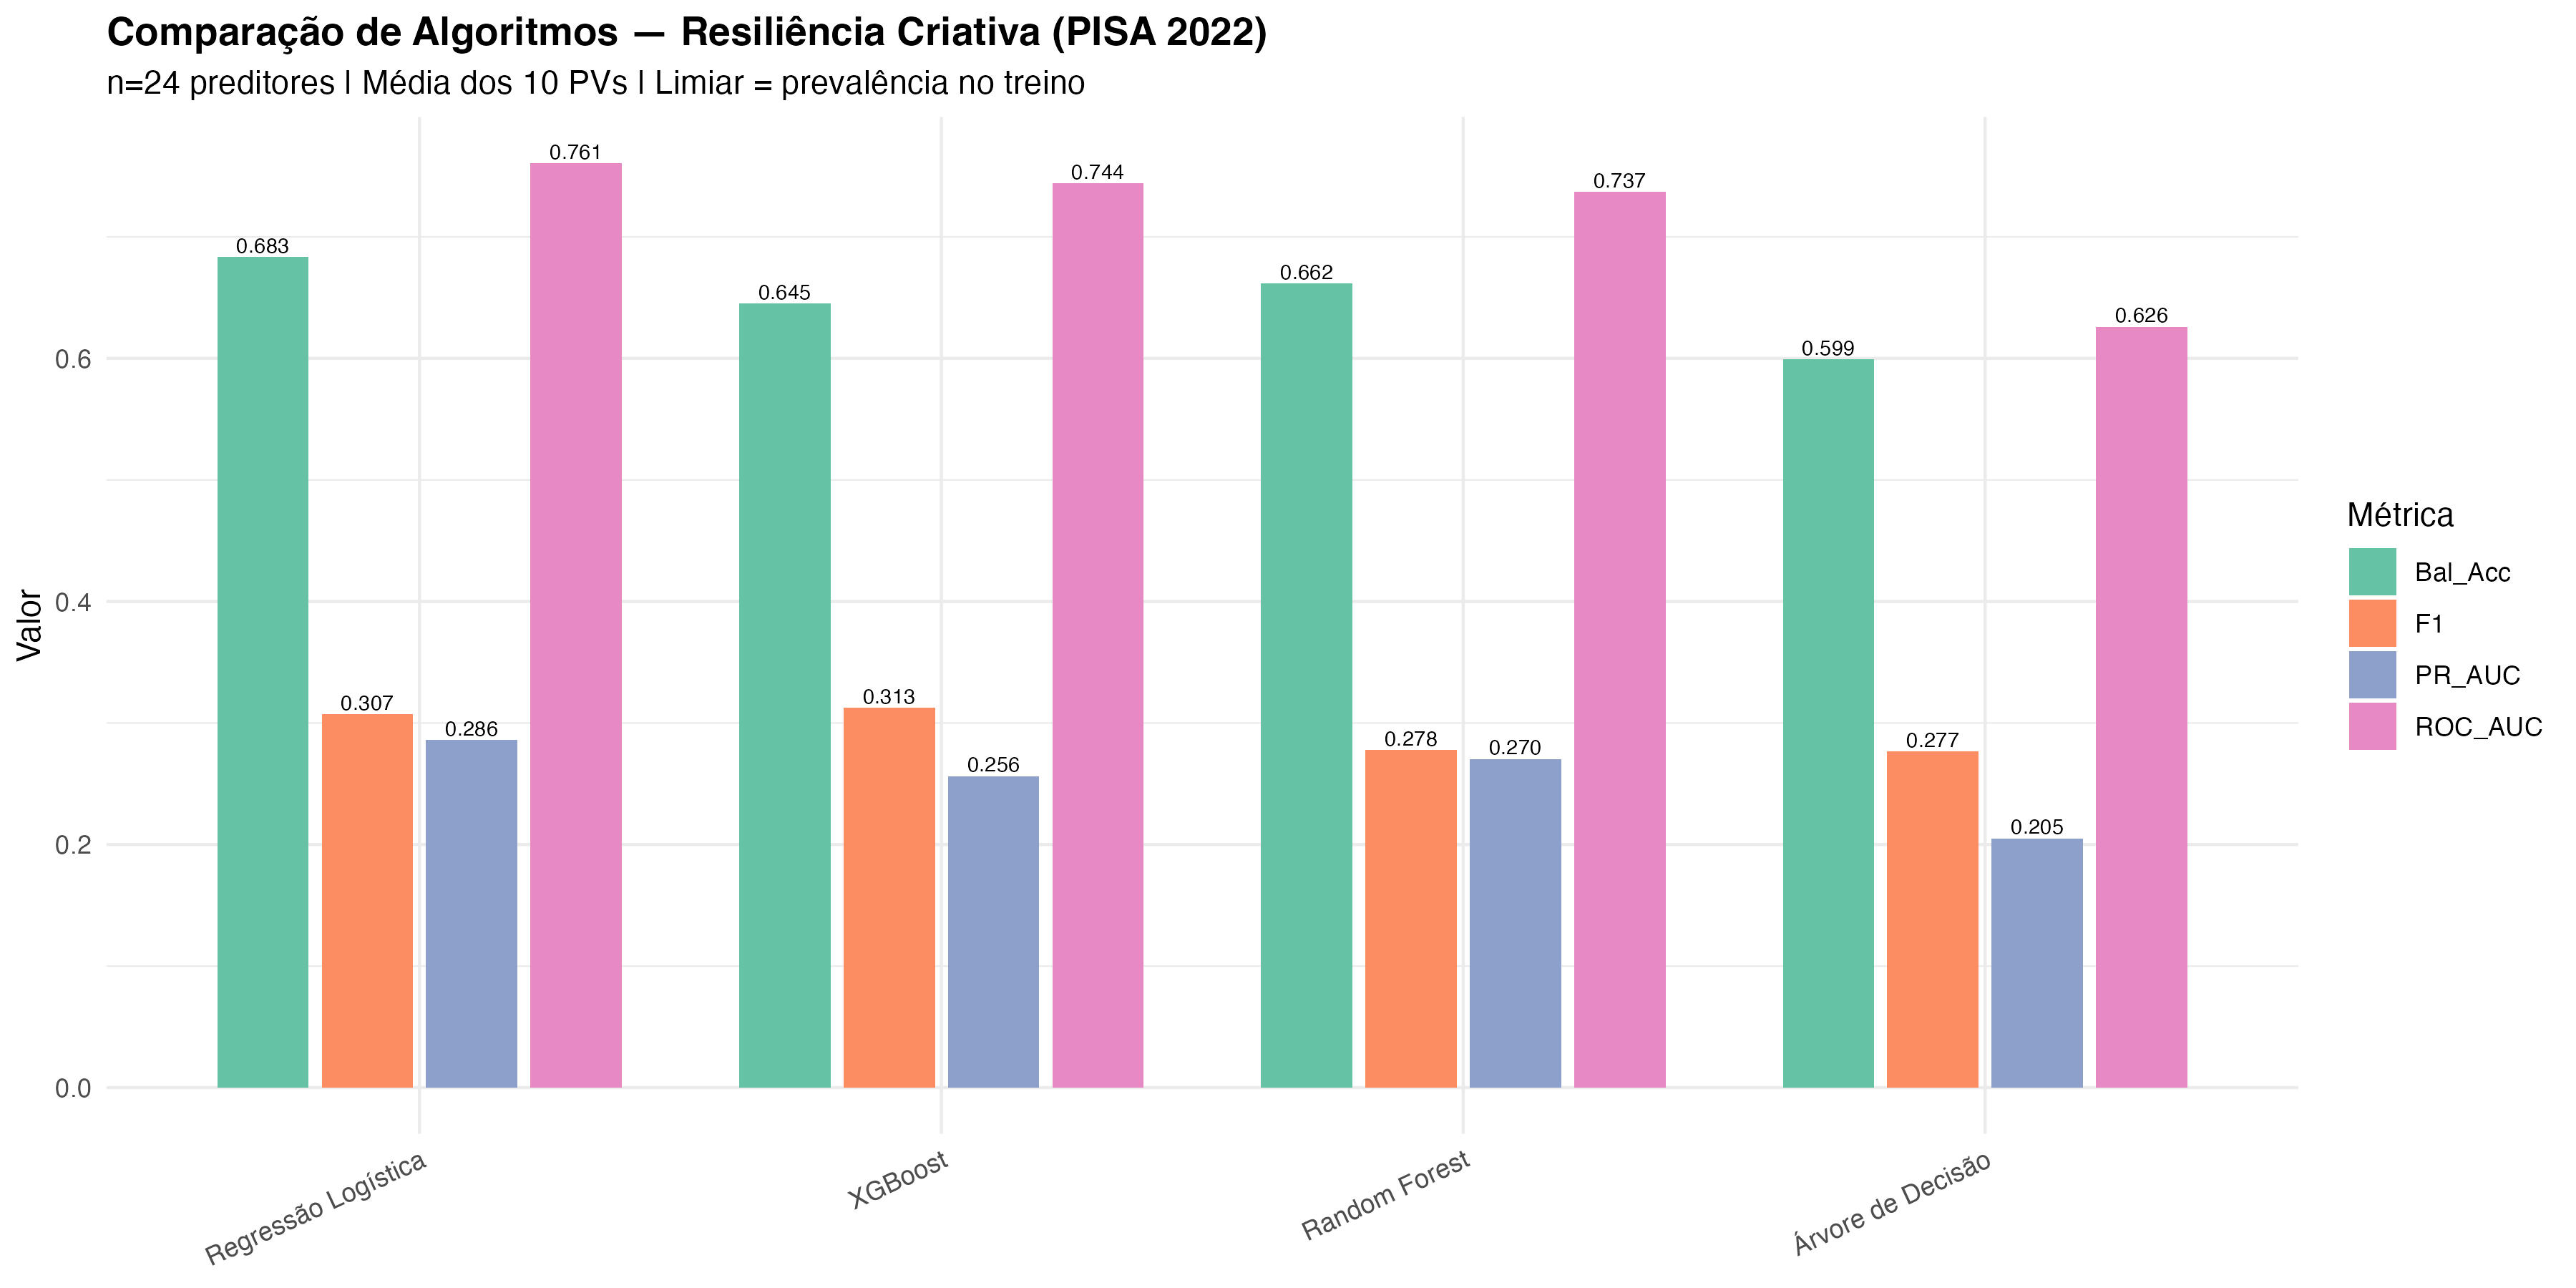

In [7]:
# ============================================================================
# CÉLULA 7: TREINAMENTO E AVALIAÇÃO DOS 4 ALGORITMOS + BOOTSTRAP CI
# ============================================================================
res_principal <- treinar_modelos(dados_vuln, tr_idx, te_idx, preditores, usar_pesos = TRUE)
tabela_principal <- agregar_rubin(res_principal$resultados)
melhor_modelo <- tabela_principal$modelo[1]

cat("\n--- Tabela Comparativa (média de 10 PVs no teste) ---\n")
print(as.data.frame(tabela_principal), row.names = FALSE)
cat("\nMelhor algoritmo (ROC-AUC):", melhor_modelo, "\n")

fwrite(tabela_principal, "results/comparacao_algoritmos.csv")
fwrite(res_principal$resultados, "results/metricas_por_pv.csv")

# Bootstrap CI para o melhor modelo (PV1, reamostrando escolas de teste)
rc_var1 <- "rc_a_pv1"
imp_boot <- imputar(
  as.data.frame(dados_vuln[tr_idx, c(preditores, rc_var1, "W_FSTUWT"), with = FALSE]),
  as.data.frame(dados_vuln[te_idx, c(preditores, rc_var1, "W_FSTUWT"), with = FALSE]),
  preditores
)
df_tr_boot <- imp_boot$tr; df_te_boot <- imp_boot$te

if (melhor_modelo == "Regressão Logística") {
  w_boot <- df_tr_boot$W_FSTUWT / mean(df_tr_boot$W_FSTUWT)
  lr_boot <- suppressWarnings(glm(df_tr_boot[[rc_var1]] ~ ., data = df_tr_boot[, preditores],
                                  family = binomial, weights = w_boot))
  p_best <- predict(lr_boot, df_te_boot[, preditores], type = "response")
} else if (melhor_modelo == "Random Forest") {
  p_best <- predict(res_principal$modelos_rf[[1]], df_te_boot[, preditores])$predictions[, "1"]
} else {
  p_best <- predict(res_principal$modelos_xgb[[1]], xgb.DMatrix(as.matrix(df_te_boot[, preditores])))
}

ci_best <- bootstrap_ci(p_best, df_te_boot[[rc_var1]], df_te_boot$W_FSTUWT, n_boot = 500,
                        cluster = dados_vuln$CNTSCHID[te_idx])
fwrite(ci_best, "results/bootstrap_ci_melhor_modelo.csv")
cat(sprintf("\nIC 95%% Cluster Bootstrap (%s, PV1): ROC-AUC [%.3f, %.3f] | PR-AUC [%.3f, %.3f] | Brier [%.3f, %.3f]\n",
            melhor_modelo, ci_best$roc_auc_lo, ci_best$roc_auc_hi,
            ci_best$pr_auc_lo, ci_best$pr_auc_hi, ci_best$brier_lo, ci_best$brier_hi))

df_plot <- tabela_principal %>%
  select(modelo, ROC_AUC_media, PR_AUC_media, F1_media, Bal_Acc_media) %>%
  tidyr::pivot_longer(-modelo, names_to = "Metrica", values_to = "Valor") %>%
  mutate(Metrica = gsub("_media", "", Metrica))
df_plot$modelo <- factor(df_plot$modelo, levels = tabela_principal$modelo)

p_comp <- ggplot(df_plot, aes(x = modelo, y = Valor, fill = Metrica)) +
  geom_bar(stat = "identity", position = position_dodge(0.8), width = 0.7) +
  geom_text(aes(label = sprintf("%.3f", Valor)), position = position_dodge(0.8), vjust = -0.3, size = 2.5) +
  scale_fill_brewer(palette = "Set2") +
  labs(title = "Comparação de Algoritmos — Resiliência Criativa (PISA 2022)",
       subtitle = paste0("n=", length(preditores), " preditores | Média dos 10 PVs | Limiar = prevalência no treino"),
       x = NULL, y = "Valor", fill = "Métrica") +
  theme_minimal(base_size = 11) +
  theme(axis.text.x = element_text(angle = 25, hjust = 1), plot.title = element_text(face = "bold"))

ggsave("figures/comparacao_algoritmos.png", p_comp, width = 12, height = 6, dpi = 300)
exibir_png("figures/comparacao_algoritmos.png")

## Etapa 8 — Análises de Sensibilidade e Ablação de Atalhos Socioeconômicos

Testa três cenários complementares nos 10 PVs:
1. Remoção dos componentes diretos do `ESCS` (`HOMEPOS`, `HISEI`, `PAREDINT` $\to$ 21 preditores);
2. Remoção conjunta do `ESCS` e das posses digitais domiciliares (`ICTRES`, `ICTAVHOM` $\to$ 19 preditores);
3. Treinamento sem pesos amostrais ($w_i = 1$).

In [8]:
# ============================================================================
# CÉLULA 8: ANÁLISES DE SENSIBILIDADE E ABLAÇÃO DE ATALHOS
# ============================================================================
res_sem_escs <- treinar_modelos(dados_vuln, tr_idx, te_idx, preditores_sem_escs,
                                usar_pesos = TRUE, label = "SemESCS")
tab_sem_escs <- agregar_rubin(res_sem_escs$resultados)
fwrite(tab_sem_escs, "results/sensibilidade_sem_escs.csv")

res_sem_escs_ict <- treinar_modelos(dados_vuln, tr_idx, te_idx, preditores_sem_escs_ict,
                                    usar_pesos = TRUE, label = "SemESCS_ICT")
tab_sem_escs_ict <- agregar_rubin(res_sem_escs_ict$resultados)
fwrite(tab_sem_escs_ict, "results/sensibilidade_sem_escs_ict.csv")

res_sem_peso <- treinar_modelos(dados_vuln, tr_idx, te_idx, preditores,
                                usar_pesos = FALSE, label = "SemPeso")
tab_sem_peso <- agregar_rubin(res_sem_peso$resultados)
fwrite(tab_sem_peso, "results/sensibilidade_sem_pesos.csv")

tab_sensibilidade <- data.frame(
  Cenario = c(
    "Principal (com pesos, 24 preditores)",
    "Sem componentes do ESCS (HOMEPOS, HISEI, PAREDINT — 21 preditores)",
    "Sem ESCS nem posses digitais domésticas (+ICTRES, ICTAVHOM — 19 preditores)",
    "Sem pesos amostrais (24 preditores)"
  ),
  Melhor_Modelo = c(melhor_modelo, tab_sem_escs$modelo[1], tab_sem_escs_ict$modelo[1], tab_sem_peso$modelo[1]),
  ROC_AUC = c(tabela_principal$ROC_AUC_media[1], tab_sem_escs$ROC_AUC_media[1],
              tab_sem_escs_ict$ROC_AUC_media[1], tab_sem_peso$ROC_AUC_media[1]),
  PR_AUC = c(tabela_principal$PR_AUC_media[1], tab_sem_escs$PR_AUC_media[1],
             tab_sem_escs_ict$PR_AUC_media[1], tab_sem_peso$PR_AUC_media[1]),
  F1 = c(tabela_principal$F1_media[1], tab_sem_escs$F1_media[1],
         tab_sem_escs_ict$F1_media[1], tab_sem_peso$F1_media[1]),
  Brier = c(tabela_principal$Brier_media[1], tab_sem_escs$Brier_media[1],
            tab_sem_escs_ict$Brier_media[1], tab_sem_peso$Brier_media[1])
)
fwrite(tab_sensibilidade, "results/sensibilidade_resumo.csv")
cat("\n--- Resumo das Análises de Sensibilidade ---\n")
print(tab_sensibilidade, row.names = FALSE)

  [SemESCS] PV 1/10
  [SemESCS] PV 2/10
  [SemESCS] PV 3/10
  [SemESCS] PV 4/10
  [SemESCS] PV 5/10
  [SemESCS] PV 6/10
  [SemESCS] PV 7/10
  [SemESCS] PV 8/10
  [SemESCS] PV 9/10
  [SemESCS] PV 10/10
  [SemESCS_ICT] PV 1/10
  [SemESCS_ICT] PV 2/10
  [SemESCS_ICT] PV 3/10
  [SemESCS_ICT] PV 4/10
  [SemESCS_ICT] PV 5/10
  [SemESCS_ICT] PV 6/10
  [SemESCS_ICT] PV 7/10
  [SemESCS_ICT] PV 8/10
  [SemESCS_ICT] PV 9/10
  [SemESCS_ICT] PV 10/10
  [SemPeso] PV 1/10
  [SemPeso] PV 2/10
  [SemPeso] PV 3/10
  [SemPeso] PV 4/10
  [SemPeso] PV 5/10
  [SemPeso] PV 6/10
  [SemPeso] PV 7/10
  [SemPeso] PV 8/10
  [SemPeso] PV 9/10
  [SemPeso] PV 10/10

--- Resumo das Análises de Sensibilidade ---
                                                                     Cenario
                                        Principal (com pesos, 24 preditores)
          Sem componentes do ESCS (HOMEPOS, HISEI, PAREDINT — 21 preditores)
 Sem ESCS nem posses digitais domésticas (+ICTRES, ICTAVHOM — 19 preditores)
   

## Etapa 9 — Inferência Populacional sob Plano Amostral (`svyglm` + Rubin + FDR)

Ajusta regressão logística multivariada padronizada (OR por 1 DP) sobre as 80 réplicas BRR nos 10 valores plausíveis combinados por `mitools::MIcombine()`, aplicando correção para múltiplas comparações de Benjamini-Hochberg ($p_{\text{BH}}$).

In [9]:
# ============================================================================
# CÉLULA 9: MODELAGEM INFERENCIAL COM DESENHO AMOSTRAL (svyglm + RUBIN + BH)
# ============================================================================
cols_inf <- c(preditores, paste0("rc_a_pv", 1:10), "W_FSTUWT", rw_names)
dados_inf <- as.data.frame(dados_vuln[, cols_inf, with = FALSE])
for (v in preditores) {
  x <- dados_inf[[v]]
  val <- if (length(unique(na.omit(x))) <= 5) get_mode(x) else median(x, na.rm = TRUE)
  x[is.na(x)] <- val
  dados_inf[[v]] <- as.numeric(scale(x))
}

fmla_x <- paste(preditores, collapse = " + ")
des_inf <- svrepdesign(data = dados_inf, weights = ~W_FSTUWT, repweights = dados_inf[, rw_names],
                       type = "Fay", rho = 0.5, combined.weights = TRUE)
ajustes <- lapply(1:10, function(i) {
  svyglm(as.formula(paste0("rc_a_pv", i, " ~ ", fmla_x)), design = des_inf, family = quasibinomial())
})

comb <- mitools::MIcombine(lapply(ajustes, coef), lapply(ajustes, vcov))
co <- coef(comb); se <- sqrt(diag(vcov(comb)))
gl <- if (is.null(comb$df) || any(!is.finite(comb$df))) rep(1e6, length(co)) else comb$df
p_val <- 2 * pt(-abs(co / se), df = gl)

df_or <- data.frame(
  variavel = names(co),
  OR = exp(co),
  OR_lo = exp(co - qt(0.975, gl) * se),
  OR_hi = exp(co + qt(0.975, gl) * se),
  p = p_val,
  row.names = NULL
)
df_or <- df_or[df_or$variavel != "(Intercept)", ]
df_or$p_BH <- p.adjust(df_or$p, method = "BH")
df_or <- df_or[order(df_or$p), ]
fwrite(df_or, "results/regressao_logistica_inferencial.csv")

cat("--- Razões de chances ajustadas por 1 DP (top 10 por valor-p) ---\n")
print(head(transform(df_or, OR = round(OR, 2), OR_lo = round(OR_lo, 2), OR_hi = round(OR_hi, 2),
                     p = round(p, 4), p_BH = round(p_BH, 4)), 10), row.names = FALSE)

--- Razões de chances ajustadas por 1 DP (top 10 por valor-p) ---
 variavel   OR OR_lo OR_hi      p   p_BH
    GRADE 1.87  1.38  2.55 0.0002 0.0059
 ICTEFFIC 1.32  1.13  1.54 0.0005 0.0059
 CURIOAGR 1.30  1.08  1.57 0.0075 0.0602
 ASSERAGR 1.23  1.04  1.47 0.0180 0.1080
  ICTFEED 0.80  0.65  0.98 0.0290 0.1393
   ICTRES 1.45  1.00  2.12 0.0520 0.2080
  ICTINFO 1.15  0.95  1.40 0.1477 0.3718
  ICTSUBJ 0.87  0.72  1.05 0.1522 0.3718
  ICTHOME 0.68  0.39  1.18 0.1617 0.3718
  HOMEPOS 1.24  0.91  1.70 0.1656 0.3718

## Etapa 10 — Interpretabilidade via TreeSHAP e Diagnóstico de Equidade por Subgrupos (*Fairness*)

Extrai os valores SHAP exatos do XGBoost sobre a **totalidade do conjunto de teste ($n = 747$)** ao longo dos 10 PVs, mede a estabilidade de postos ($\bar{\rho}_{\text{Spearman}}$) e audita discriminação, calibração e taxas de erro (`FPR`/`FNR`) por sexo, adequação idade-série e acesso digital.

Concordância média de posto (Spearman) do SHAP entre os 10 PVs: 0.824
 Variavel   SHAP  DP_PV   Rho
   ICTRES 0.4590 0.0976  0.97
    GRADE 0.4375 0.0618  0.91
 CURIOAGR 0.3211 0.0761  0.74
 ICTEFFIC 0.3058 0.0771  0.88
 ASSERAGR 0.2701 0.0678  0.42
  HOMEPOS 0.2141 0.0675  0.60
   ICTOUT 0.1876 0.0912  0.58
  ICTWKDY 0.1729 0.0392 -0.54
  ICTFEED 0.1506 0.0301 -0.91
  ICTINFO 0.1413 0.0883  0.91

--- Diagnóstico de Subgrupos (Fairness no Teste) ---
                                   Subgrupo N_Teste Prev_Obs_Pct Prob_Pred_Pct
      Recursos TIC: Alto (ICTRES > mediana)     353         15.5          18.0
    Recursos TIC: Baixo (ICTRES <= mediana)     394          6.0           8.2
                             Sexo: Feminino     400         11.7          14.6
                            Sexo: Masculino     347          8.9          10.7
          Trajetória: Defasagem (GRADE < 0)     170          2.4           4.3
 Trajetória: Regular/Adiantado (GRADE >= 0)     577         13.0        

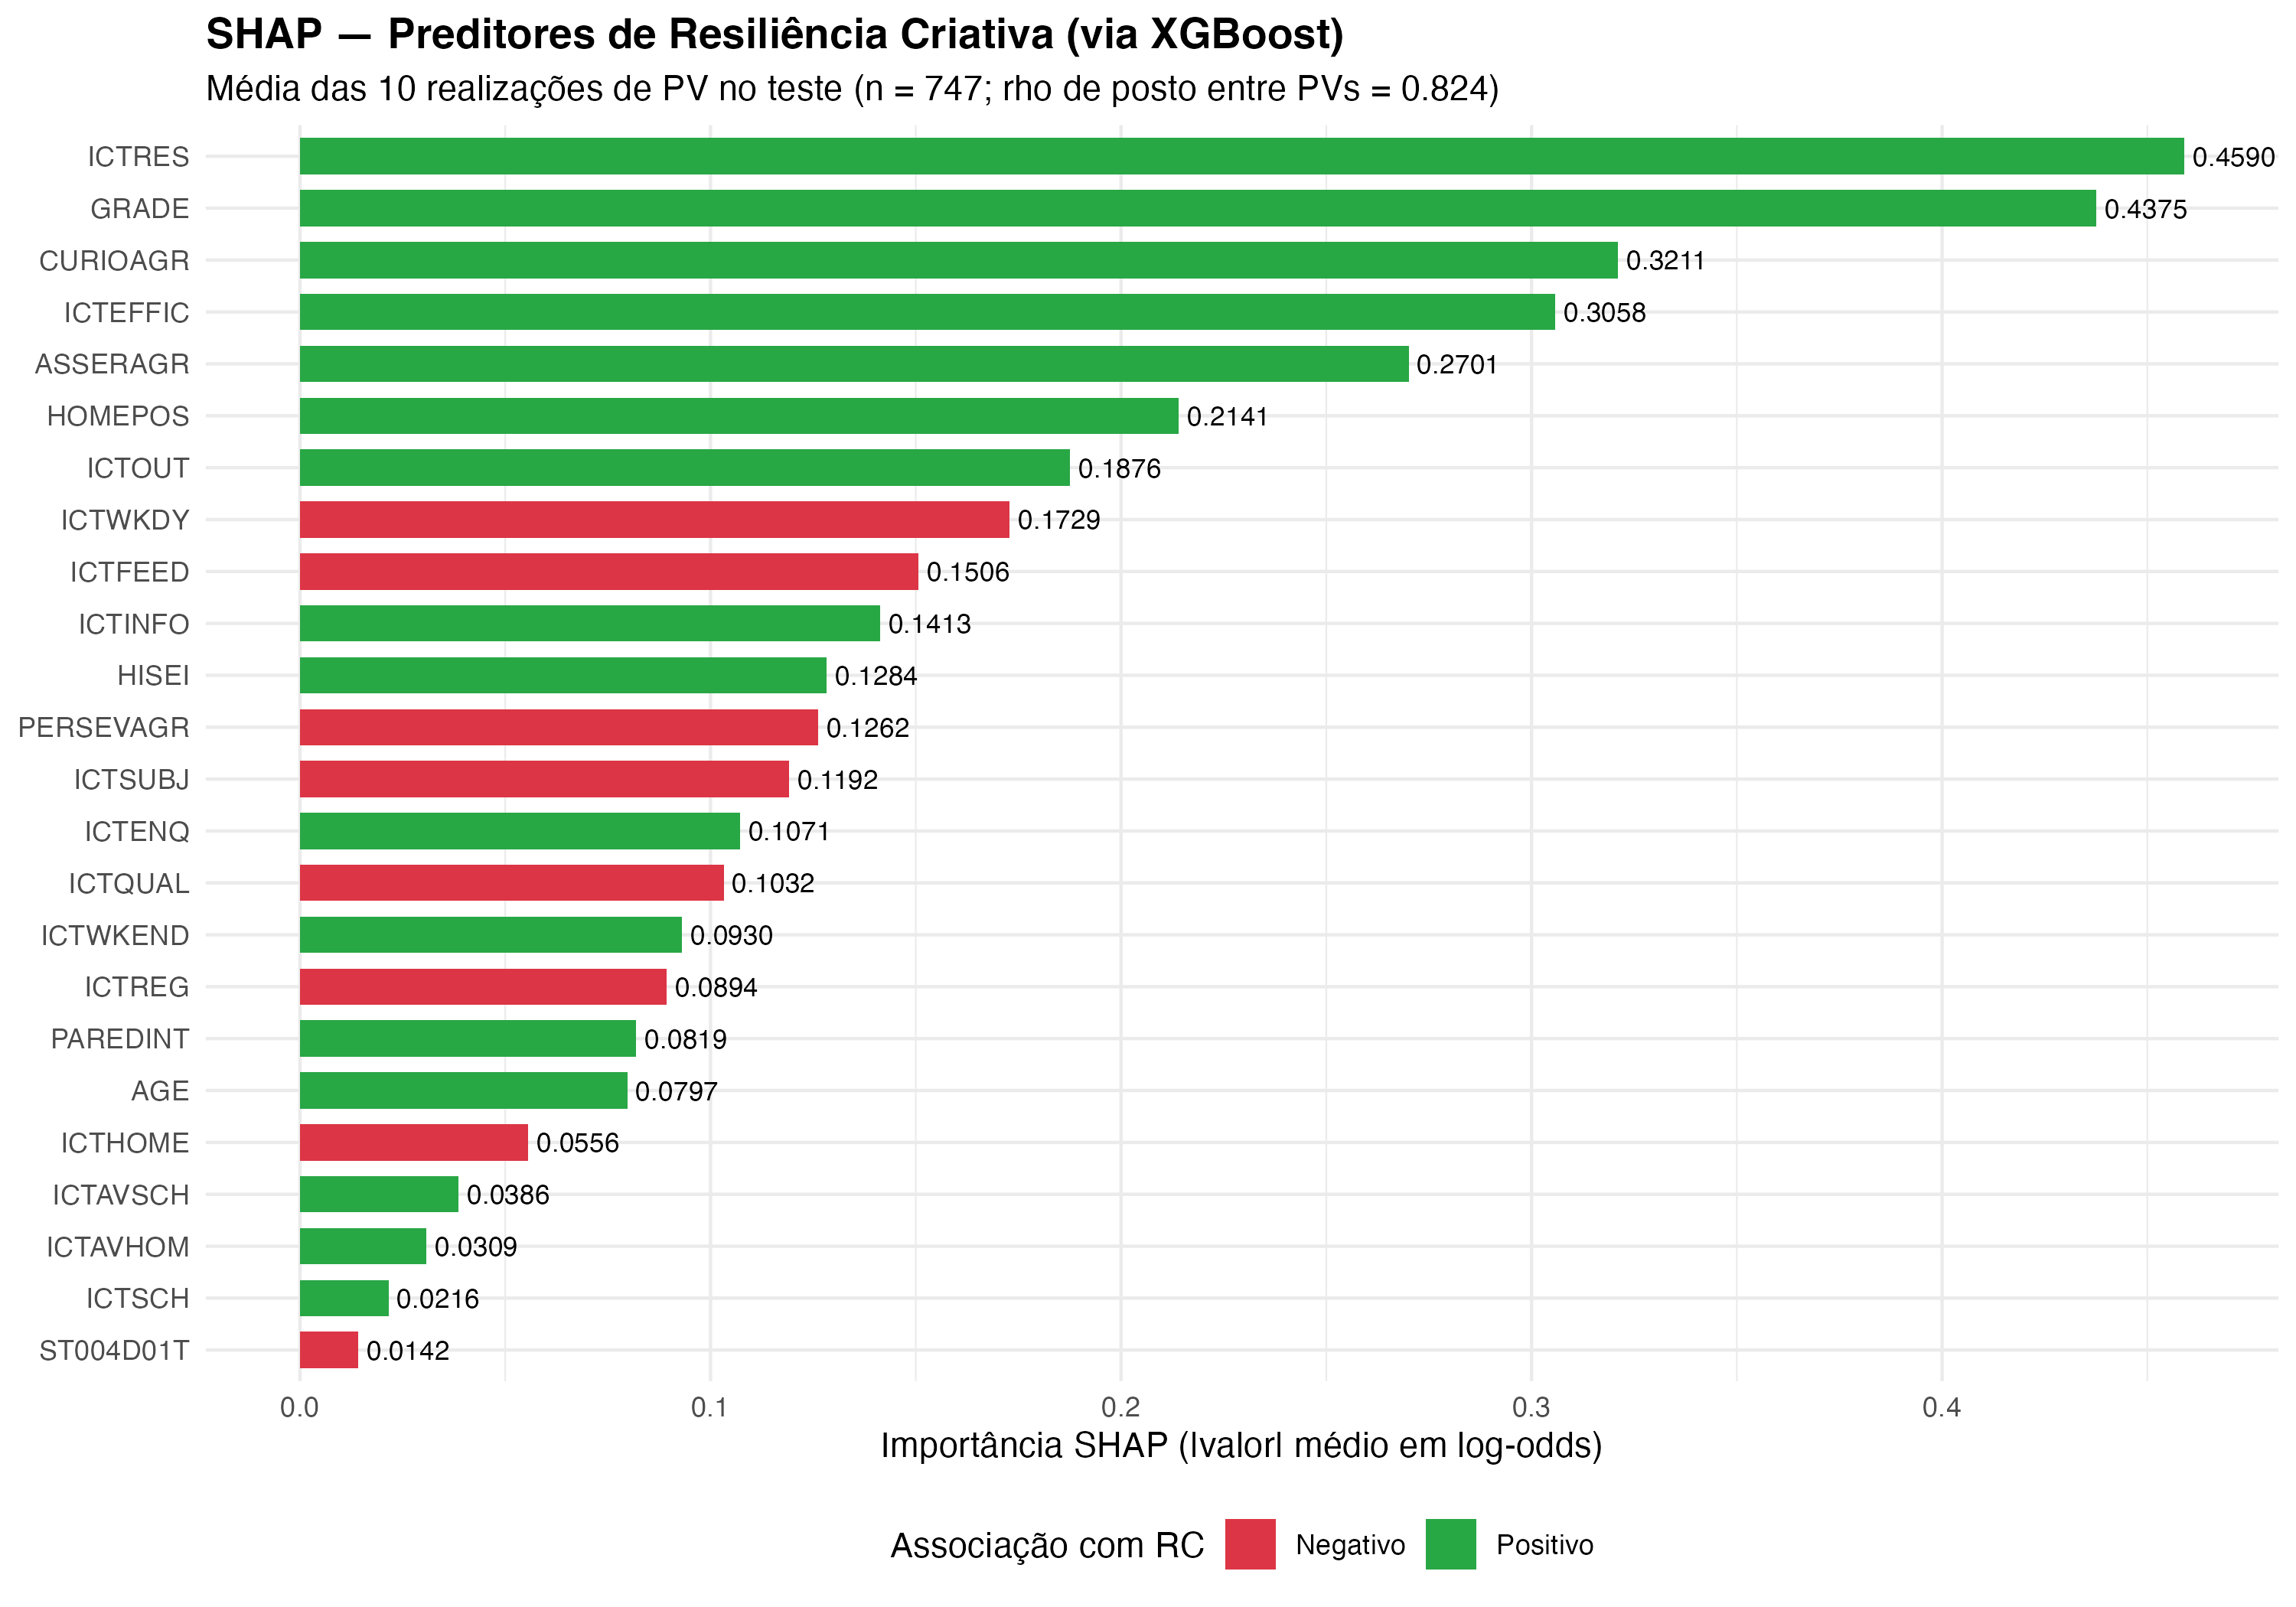

In [10]:
# ============================================================================
# CÉLULA 10: TREESHAP NO CONJUNTO DE TESTE (10 PVs) + FAIRNESS POR SUBGRUPOS
# ============================================================================
X_shap <- res_principal$X_te
n_shap <- nrow(X_shap)
matrizes_shap <- list()
mat_imp_pv <- matrix(NA_real_, nrow = ncol(X_shap), ncol = 10,
                     dimnames = list(colnames(X_shap), paste0("PV", 1:10)))

for (i in 1:10) {
  shap_contrib <- predict(res_principal$modelos_xgb[[i]], xgb.DMatrix(as.matrix(X_shap)), predcontrib = TRUE)
  df_sc <- as.data.frame(shap_contrib[, -ncol(shap_contrib)])
  matrizes_shap[[i]] <- df_sc
  mat_imp_pv[, i] <- colMeans(abs(df_sc))
}

shap_final <- as.data.frame(Reduce("+", matrizes_shap) / 10)
shap_imp <- sort(colMeans(abs(shap_final)), decreasing = TRUE)
shap_dp_pv <- apply(mat_imp_pv[names(shap_imp), , drop = FALSE], 1, sd)

cor_pairs_shap <- cor(mat_imp_pv, method = "spearman")
rho_rank_shap <- mean(cor_pairs_shap[upper.tri(cor_pairs_shap)])
cat(sprintf("Concordância média de posto (Spearman) do SHAP entre os 10 PVs: %.3f\n", rho_rank_shap))

X_shap_df <- as.data.frame(X_shap)
shap_dir <- sapply(names(shap_imp), function(v) {
  c <- cor(X_shap_df[, v], shap_final[, v], method = "spearman", use = "complete.obs")
  if (is.na(c)) 0 else c
})

df_shap <- data.frame(
  variavel = names(shap_imp),
  importancia = as.numeric(shap_imp),
  dp_entre_pvs = as.numeric(shap_dp_pv),
  direcao_spearman = as.numeric(shap_dir[names(shap_imp)]),
  efeito = ifelse(shap_dir[names(shap_imp)] > 0, "Positivo", "Negativo")
)
df_shap$variavel <- factor(df_shap$variavel, levels = rev(df_shap$variavel))
fwrite(df_shap, "results/shap_importancia.csv")

print(head(data.frame(Variavel = names(shap_imp), SHAP = round(as.numeric(shap_imp), 4),
                      DP_PV = round(as.numeric(shap_dp_pv), 4),
                      Rho = round(as.numeric(shap_dir[names(shap_imp)]), 2)), 10), row.names = FALSE)

p_shap <- ggplot(df_shap, aes(x = importancia, y = variavel, fill = efeito)) +
  geom_bar(stat = "identity", width = 0.7) +
  geom_text(aes(label = sprintf("%.4f", importancia)), hjust = -0.1, size = 3) +
  scale_fill_manual(values = c("Positivo" = "#28a745", "Negativo" = "#dc3545")) +
  labs(title = "SHAP — Preditores de Resiliência Criativa (via XGBoost)",
       subtitle = sprintf("Média das 10 realizações de PV no teste (n = %d; rho de posto entre PVs = %.3f)", n_shap, rho_rank_shap),
       x = "Importância SHAP (|valor| médio em log-odds)", y = NULL, fill = "Associação com RC") +
  theme_minimal(base_size = 11) +
  theme(legend.position = "bottom", plot.title = element_text(face = "bold"))

ggsave("figures/shap_preditores.png", p_shap, width = 10, height = 7, dpi = 300)
exibir_png("figures/shap_preditores.png")

# Diagnóstico de equidade por subgrupos (fairness)
res_sub <- list()
for (i in 1:10) {
  rc_var <- paste0("rc_a_pv", i)
  imp <- imputar(
    as.data.frame(dados_vuln[tr_idx, c(preditores, rc_var, "W_FSTUWT"), with = FALSE]),
    as.data.frame(dados_vuln[te_idx, c(preditores, rc_var, "W_FSTUWT"), with = FALSE]),
    preditores
  )
  df_tr <- imp$tr; df_te <- imp$te
  y_tr <- df_tr[[rc_var]]; y_te <- df_te[[rc_var]]
  w_tr <- df_tr$W_FSTUWT / mean(df_tr$W_FSTUWT); w_te <- df_te$W_FSTUWT
  limiar <- weighted.mean(y_tr, w_tr)

  lr <- suppressWarnings(glm(y_tr ~ ., data = df_tr[, preditores], family = binomial, weights = w_tr))
  p_lr <- predict(lr, df_te[, preditores], type = "response"); p_lr[is.na(p_lr)] <- 0.5
  med_ict <- median(df_tr$ICTRES, na.rm = TRUE)

  grupos <- list(
    "Sexo: Feminino" = which(df_te$ST004D01T == 1),
    "Sexo: Masculino" = which(df_te$ST004D01T == 2),
    "Trajetória: Defasagem (GRADE < 0)" = which(df_te$GRADE < 0),
    "Trajetória: Regular/Adiantado (GRADE >= 0)" = which(df_te$GRADE >= 0),
    "Recursos TIC: Baixo (ICTRES <= mediana)" = which(df_te$ICTRES <= med_ict),
    "Recursos TIC: Alto (ICTRES > mediana)" = which(df_te$ICTRES > med_ict)
  )
  for (nm in names(grupos)) {
    idx_g <- grupos[[nm]]
    if (length(idx_g) >= 20 && sum(y_te[idx_g] == 1) >= 2) {
      m_g <- calc_metricas(p_lr[idx_g], y_te[idx_g], w_te[idx_g], limiar)
      m_g$Subgrupo <- nm; m_g$N_Teste <- length(idx_g)
      m_g$Prev_Observada <- weighted.mean(y_te[idx_g], w_te[idx_g])
      m_g$Prob_Media_Predita <- weighted.mean(p_lr[idx_g], w_te[idx_g])
      m_g$FPR <- 1 - m_g$specificity; m_g$FNR <- 1 - m_g$recall; m_g$pv <- i
      res_sub[[length(res_sub) + 1]] <- m_g
    }
  }
}

tab_fairness <- do.call(rbind, res_sub) %>%
  group_by(Subgrupo) %>%
  summarise(
    N_Teste = first(N_Teste),
    Prev_Obs_Pct = round(mean(Prev_Observada, na.rm = TRUE) * 100, 1),
    Prob_Pred_Pct = round(mean(Prob_Media_Predita, na.rm = TRUE) * 100, 1),
    ROC_AUC = round(mean(roc_auc, na.rm = TRUE), 3),
    PR_AUC = round(mean(pr_auc, na.rm = TRUE), 3),
    Brier = round(mean(brier, na.rm = TRUE), 3),
    Sensibilidade_TPR = round(mean(recall, na.rm = TRUE), 3),
    Especificidade_TNR = round(mean(specificity, na.rm = TRUE), 3),
    FPR = round(mean(FPR, na.rm = TRUE), 3),
    FNR = round(mean(FNR, na.rm = TRUE), 3),
    .groups = "drop"
  )
fwrite(tab_fairness, "results/fairness_subgrupos.csv")
cat("\n--- Diagnóstico de Subgrupos (Fairness no Teste) ---\n")
print(as.data.frame(tab_fairness), row.names = FALSE)

## Etapa 11 — Reprodutibilidade e Transportabilidade Transnacional (`BRA`, `CHL`, `URY`, `SGP`) e Exportação Final

Avalia o pipeline em Chile, Uruguai e Singapura (treinamento local com 24 e 19 preditores, correlação de Spearman dos coeficientes padronizados com o Brasil e transporte direto $\text{BRA} \rightarrow k$ com *recalibration-in-the-large*), exportando `results/resultados_completos.md`, `results/results_for_paper.rds` e `results/session_info.txt`.

      Pais Codigo N_Total N_Vulneraveis N_Escolas Q1_ESCS Q3_PV_Medio
    Brasil    BRA   10334          2530       504   -1.75        31.9
     Chile    CHL    6181          1210       165   -1.18        39.0
   Uruguai    URY    6508          1608       198   -1.68        36.7
 Singapura    SGP    6559          1667       156   -0.22        48.5
 Prop_Resilientes_DefA_Pct Prop_Nivel3_OCDE_Pct ROC_Local_LR ROC_Local_RF
                      11.9                 11.7        0.761        0.737
                      17.2                 33.9        0.670        0.680
                      11.7                 21.0        0.739        0.771
                      10.1                 65.2        0.701        0.693
 ROC_Local_XGB ROC_Local_SemAtalhos19 PR_Local_LR Brier_Local_LR
         0.744                  0.721       0.286          0.085
         0.673                  0.668       0.291          0.129
         0.751                  0.740       0.228          0.102
         0.696      

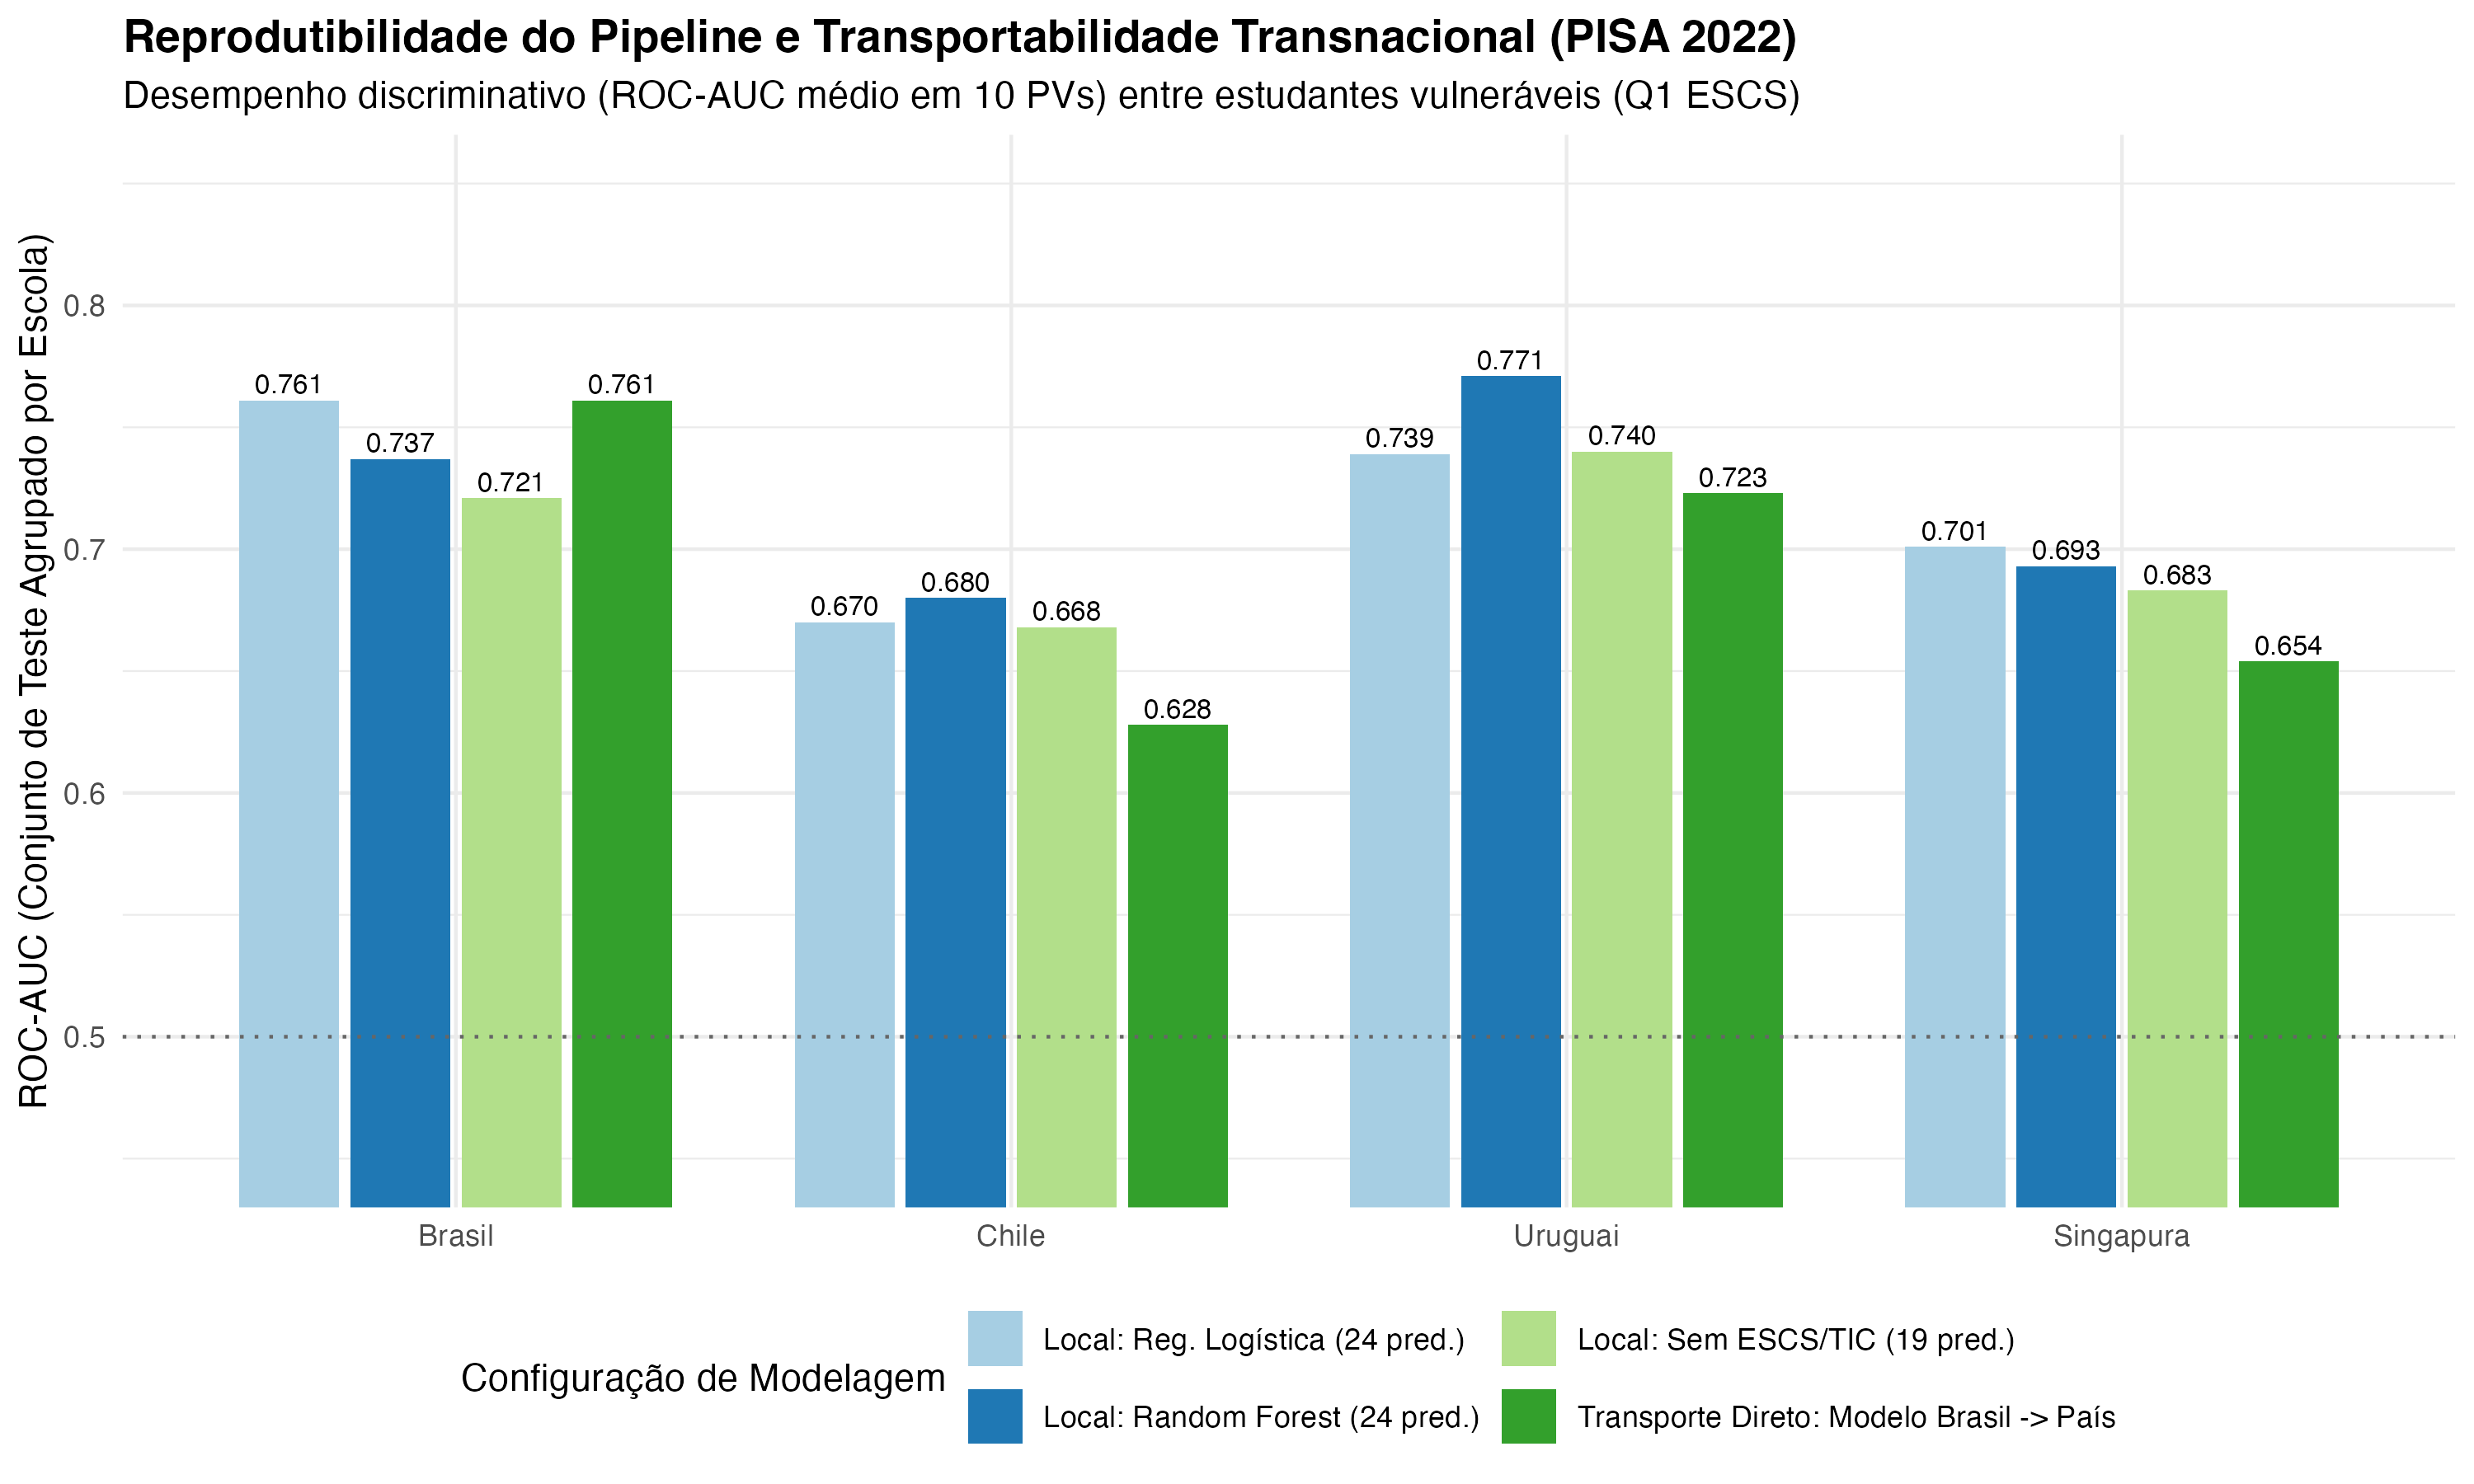

In [11]:
# ============================================================================
# CÉLULA 11: TRANSPORTABILIDADE TRANSNACIONAL E EXPORTAÇÃO FINAL
# ============================================================================
mc_path <- file.path(CAMINHO_DADOS, "pisa2022_multicountry.rds")
if (file.exists(mc_path)) {
  dt_mc <- as.data.table(readRDS(mc_path))
  paises <- c("BRA", "CHL", "URY", "SGP")
  nomes_paises <- c(BRA = "Brasil", CHL = "Chile", URY = "Uruguai", SGP = "Singapura")

  prep_pais <- function(cnt_code) {
    if (cnt_code == "BRA") {
      return(list(
        cnt = "BRA", nome = "Brasil",
        n_total = nrow(dados_escs_val), n_vuln = nrow(dados_vuln),
        n_escolas = length(unique(dados_vuln$CNTSCHID)),
        q1_escs = as.numeric(q1_escs), q3_pv_medio = mean(q3_ct),
        prev_a = mean(prev_a), prev_niv3 = mean(prev_niv3),
        dv = dados_vuln, tr_idx = tr_idx, te_idx = te_idx
      ))
    }
    d <- dt_mc[CNT == cnt_code & !is.na(PV1CRTH_NC) & !is.na(W_FSTUWT)]
    setorder(d, CNTSTUID)
    q1_c <- wtd.quantile(d$ESCS, d$W_FSTUWT, 0.25, na.rm = TRUE)
    d$vulneravel <- ifelse(!is.na(d$ESCS) & d$ESCS <= q1_c, 1L, 0L)
    q3_pvs <- numeric(10)
    for (i in 1:10) {
      pv_col <- paste0("PV", i, "CRTH_NC")
      q3_pvs[i] <- wtd.quantile(d[[pv_col]], d$W_FSTUWT, 0.75, na.rm = TRUE)
      d[[paste0("rc_a_pv", i)]] <- ifelse(d$vulneravel == 1 & d[[pv_col]] >= q3_pvs[i], 1L, 0L)
      d[[paste0("rc_niv3_pv", i)]] <- ifelse(d$vulneravel == 1 & d[[pv_col]] >= 32.0, 1L, 0L)
    }
    dv <- d[vulneravel == 1]
    set.seed(2024)
    esc <- unique(dv$CNTSCHID)
    esc_tr <- sample(esc, floor(length(esc) * 0.7))
    tr_i <- which(dv$CNTSCHID %in% esc_tr)
    te_i <- setdiff(seq_len(nrow(dv)), tr_i)
    list(
      cnt = cnt_code, nome = nomes_paises[[cnt_code]],
      n_total = sum(!is.na(d$ESCS)), n_vuln = nrow(dv), n_escolas = length(esc),
      q1_escs = as.numeric(q1_c), q3_pv_medio = mean(q3_pvs),
      prev_a = mean(sapply(1:10, function(i) weighted.mean(dv[[paste0("rc_a_pv", i)]], dv$W_FSTUWT, na.rm = TRUE))),
      prev_niv3 = mean(sapply(1:10, function(i) weighted.mean(dv[[paste0("rc_niv3_pv", i)]], dv$W_FSTUWT, na.rm = TRUE))),
      dv = dv, tr_idx = tr_i, te_idx = te_i
    )
  }

  lista_paises <- lapply(paises, prep_pais)
  names(lista_paises) <- paises

  res_transp <- list(); coefs_paises <- list()
  for (cnt_code in paises) {
    lp <- lista_paises[[cnt_code]]
    dv <- lp$dv; tr_i <- lp$tr_idx; te_i <- lp$te_idx
    roc_loc_lr <- pr_loc_lr <- brier_loc_lr <- roc_loc_rf <- roc_loc_xgb <- numeric(10)
    roc_sem19_lr <- roc_tr_lr <- pr_tr_lr <- brier_tr_raw <- brier_tr_recal <- numeric(10)
    mat_coef_k <- matrix(NA_real_, nrow = length(preditores), ncol = 10,
                         dimnames = list(preditores, paste0("PV", 1:10)))

    for (i in 1:10) {
      rc_var <- paste0("rc_a_pv", i)
      imp_k <- imputar(
        as.data.frame(dv[tr_i, c(preditores, rc_var, "W_FSTUWT"), with = FALSE]),
        as.data.frame(dv[te_i, c(preditores, rc_var, "W_FSTUWT"), with = FALSE]),
        preditores
      )
      df_tr_k <- imp_k$tr; df_te_k <- imp_k$te
      y_tr_k <- df_tr_k[[rc_var]]; y_te_k <- df_te_k[[rc_var]]
      w_tr_k <- df_tr_k$W_FSTUWT / mean(df_tr_k$W_FSTUWT); w_te_k <- df_te_k$W_FSTUWT
      prev_tr_k <- weighted.mean(y_tr_k, w_tr_k)

      lr_k <- suppressWarnings(glm(y_tr_k ~ ., data = df_tr_k[, preditores], family = binomial, weights = w_tr_k))
      p_lr_k <- predict(lr_k, df_te_k[, preditores], type = "response"); p_lr_k[is.na(p_lr_k)] <- 0.5
      m_lr_k <- calc_metricas(p_lr_k, y_te_k, w_te_k, prev_tr_k)
      roc_loc_lr[i] <- m_lr_k$roc_auc; pr_loc_lr[i] <- m_lr_k$pr_auc; brier_loc_lr[i] <- m_lr_k$brier

      rf_k <- ranger(x = df_tr_k[, preditores], y = factor(y_tr_k, levels = c("0", "1")), num.trees = 500,
                     case.weights = w_tr_k, probability = TRUE, seed = 2024 + i)
      p_rf_k <- predict(rf_k, df_te_k[, preditores])$predictions[, "1"]
      roc_loc_rf[i] <- calc_metricas(p_rf_k, y_te_k, w_te_k, prev_tr_k)$roc_auc

      dtr_k <- xgb.DMatrix(as.matrix(df_tr_k[, preditores]), label = y_tr_k, weight = w_tr_k)
      xgb_k <- xgb.train(params = list(objective = "binary:logistic", max_depth = 6, eta = 0.1),
                         data = dtr_k, nrounds = 150, verbose = 0)
      p_xgb_k <- predict(xgb_k, xgb.DMatrix(as.matrix(df_te_k[, preditores])))
      roc_loc_xgb[i] <- calc_metricas(p_xgb_k, y_te_k, w_te_k, prev_tr_k)$roc_auc

      lr_19 <- suppressWarnings(glm(y_tr_k ~ ., data = df_tr_k[, preditores_sem_escs_ict], family = binomial, weights = w_tr_k))
      p_19 <- predict(lr_19, df_te_k[, preditores_sem_escs_ict], type = "response"); p_19[is.na(p_19)] <- 0.5
      roc_sem19_lr[i] <- calc_metricas(p_19, y_te_k, w_te_k, prev_tr_k)$roc_auc

      X_std_k <- as.data.frame(scale(df_tr_k[, preditores]))
      lr_std_k <- suppressWarnings(glm(y_tr_k ~ ., data = X_std_k, family = binomial, weights = w_tr_k))
      mat_coef_k[, i] <- coef(lr_std_k)[preditores]

      lp_bra <- lista_paises[["BRA"]]
      df_tr_bra_raw <- as.data.frame(lp_bra$dv[lp_bra$tr_idx, c(preditores, rc_var, "W_FSTUWT"), with = FALSE])
      imp_tr_te <- imputar(df_tr_bra_raw, as.data.frame(dv[te_i, c(preditores, rc_var, "W_FSTUWT"), with = FALSE]), preditores)
      imp_tr_tr <- imputar(df_tr_bra_raw, as.data.frame(dv[tr_i, c(preditores, rc_var, "W_FSTUWT"), with = FALSE]), preditores)
      w_tr_bra <- imp_tr_te$tr$W_FSTUWT / mean(imp_tr_te$tr$W_FSTUWT)
      y_tr_bra <- imp_tr_te$tr[[rc_var]]

      lr_bra <- suppressWarnings(glm(y_tr_bra ~ ., data = imp_tr_te$tr[, preditores], family = binomial, weights = w_tr_bra))
      eta_te_k <- predict(lr_bra, imp_tr_te$te[, preditores], type = "link"); eta_te_k[is.na(eta_te_k)] <- 0
      eta_tr_k <- predict(lr_bra, imp_tr_tr$te[, preditores], type = "link"); eta_tr_k[is.na(eta_tr_k)] <- 0
      p_tr_raw <- plogis(eta_te_k)

      recal_fit <- suppressWarnings(glm(y_tr_k ~ 1 + offset(eta_tr_k), family = binomial, weights = w_tr_k))
      alpha_recal <- as.numeric(coef(recal_fit)[1])
      p_tr_recal <- plogis(alpha_recal + eta_te_k)

      m_tr <- calc_metricas(p_tr_raw, y_te_k, w_te_k, prev_tr_k)
      roc_tr_lr[i] <- m_tr$roc_auc; pr_tr_lr[i] <- m_tr$pr_auc
      brier_tr_raw[i] <- weighted.mean((p_tr_raw - y_te_k)^2, w_te_k)
      brier_tr_recal[i] <- weighted.mean((p_tr_recal - y_te_k)^2, w_te_k)
    }

    coefs_paises[[cnt_code]] <- rowMeans(mat_coef_k, na.rm = TRUE)
    res_transp[[cnt_code]] <- data.frame(
      Pais = lp$nome, Codigo = cnt_code, N_Total = lp$n_total,
      N_Vulneraveis = lp$n_vuln, N_Escolas = lp$n_escolas,
      Q1_ESCS = round(lp$q1_escs, 2), Q3_PV_Medio = round(lp$q3_pv_medio, 1),
      Prop_Resilientes_DefA_Pct = round(lp$prev_a * 100, 1),
      Prop_Nivel3_OCDE_Pct = round(lp$prev_niv3 * 100, 1),
      ROC_Local_LR = round(mean(roc_loc_lr, na.rm = TRUE), 3),
      ROC_Local_RF = round(mean(roc_loc_rf, na.rm = TRUE), 3),
      ROC_Local_XGB = round(mean(roc_loc_xgb, na.rm = TRUE), 3),
      ROC_Local_SemAtalhos19 = round(mean(roc_sem19_lr, na.rm = TRUE), 3),
      PR_Local_LR = round(mean(pr_loc_lr, na.rm = TRUE), 3),
      Brier_Local_LR = round(mean(brier_loc_lr, na.rm = TRUE), 3),
      ROC_Transporte_BRA = round(mean(roc_tr_lr, na.rm = TRUE), 3),
      PR_Transporte_BRA = round(mean(pr_tr_lr, na.rm = TRUE), 3),
      Brier_Transporte_Bruto = round(mean(brier_tr_raw, na.rm = TRUE), 3),
      Brier_Transporte_Recal = round(mean(brier_tr_recal, na.rm = TRUE), 3)
    )
  }

  tab_transp <- do.call(rbind, res_transp)
  tab_transp$Rho_Coefs_vs_BRA <- sapply(paises, function(cnt) {
    round(cor(coefs_paises[["BRA"]], coefs_paises[[cnt]], method = "spearman", use = "complete.obs"), 3)
  })
  fwrite(tab_transp, "results/transportabilidade_paises.csv")
  print(tab_transp, row.names = FALSE)

  df_coefs_comp <- data.frame(
    Variavel = preditores,
    Beta_BRA = round(coefs_paises[["BRA"]], 3), Beta_CHL = round(coefs_paises[["CHL"]], 3),
    Beta_URY = round(coefs_paises[["URY"]], 3), Beta_SGP = round(coefs_paises[["SGP"]], 3),
    row.names = NULL
  )
  fwrite(df_coefs_comp, "results/importancia_comparada_paises.csv")

  df_plot_tr <- tab_transp %>%
    select(Pais, ROC_Local_LR, ROC_Local_RF, ROC_Local_SemAtalhos19, ROC_Transporte_BRA) %>%
    tidyr::pivot_longer(-Pais, names_to = "Cenario", values_to = "ROC_AUC") %>%
    mutate(
      Cenario = factor(Cenario,
        levels = c("ROC_Local_LR", "ROC_Local_RF", "ROC_Local_SemAtalhos19", "ROC_Transporte_BRA"),
        labels = c("Local: Reg. Logística (24 pred.)", "Local: Random Forest (24 pred.)",
                   "Local: Sem ESCS/TIC (19 pred.)", "Transporte Direto: Modelo Brasil -> País")
      ),
      Pais = factor(Pais, levels = c("Brasil", "Chile", "Uruguai", "Singapura"))
    )

  p_transp <- ggplot(df_plot_tr, aes(x = Pais, y = ROC_AUC, fill = Cenario)) +
    geom_bar(stat = "identity", position = position_dodge(0.8), width = 0.72) +
    geom_hline(yintercept = 0.50, linetype = "dotted", color = "gray40") +
    geom_text(aes(label = sprintf("%.3f", ROC_AUC)), position = position_dodge(0.8), vjust = -0.35, size = 2.8) +
    scale_fill_brewer(palette = "Paired") +
    coord_cartesian(ylim = c(0.45, 0.85)) +
    labs(title = "Reprodutibilidade do Pipeline e Transportabilidade Transnacional (PISA 2022)",
         subtitle = "Desempenho discriminativo (ROC-AUC médio em 10 PVs) entre estudantes vulneráveis (Q1 ESCS)",
         x = NULL, y = "ROC-AUC (Conjunto de Teste Agrupado por Escola)", fill = "Configuração de Modelagem") +
    theme_minimal(base_size = 11) +
    theme(legend.position = "bottom", plot.title = element_text(face = "bold")) +
    guides(fill = guide_legend(nrow = 2))

  ggsave("figures/transportabilidade_paises.png", p_transp, width = 10, height = 6, dpi = 300)
  exibir_png("figures/transportabilidade_paises.png")
} else {
  cat("[AVISO] pisa2022_multicountry.rds não encontrado; etapa transnacional ignorada.\n")
}

# Exportações finais (RDS + sessionInfo + Markdown resumo)
resultados_paper <- list(
  n_students = nrow(dados), n_escs_validos = nrow(dados_escs_val),
  n_vulneraveis = nrow(dados_vuln), n_escolas = length(unique(dados_vuln$CNTSCHID)),
  q1_escs = q1_escs, prev_pop_total = mean(prev_pop_total) * 100,
  prevalencia = prev_media * 100, prevalencia_se = ep_consolidado * 100,
  prevalencia_ic_lo = (prev_media - 1.96 * ep_consolidado) * 100,
  prevalencia_ic_hi = (prev_media + 1.96 * ep_consolidado) * 100,
  prev_def_a = mean(prev_a) * 100, prev_def_b = mean(prev_b) * 100, prev_niv3 = mean(prev_niv3) * 100,
  melhor_modelo = melhor_modelo, roc_auc_media = tabela_principal$ROC_AUC_media[1],
  roc_auc_dp = tabela_principal$ROC_AUC_dp[1], pr_auc_media = tabela_principal$PR_AUC_media[1],
  f1_media = tabela_principal$F1_media[1], brier_media = tabela_principal$Brier_media[1],
  roc_auc_ci_lo = as.numeric(ci_best$roc_auc_lo), roc_auc_ci_hi = as.numeric(ci_best$roc_auc_hi),
  top_5_shap = paste(names(shap_imp)[1:5], collapse = ", "), rho_rank_shap = rho_rank_shap,
  sensib_sem_escs_roc = tab_sem_escs$ROC_AUC_media[1],
  sensib_sem_escs_ict_roc = tab_sem_escs_ict$ROC_AUC_media[1],
  sensib_sem_peso_roc = tab_sem_peso$ROC_AUC_media[1]
)
saveRDS(resultados_paper, "results/results_for_paper.rds")
writeLines(capture.output(sessionInfo()), "results/session_info.txt")

cat("\n=== PIPELINE CONCLUÍDO COM SUCESSO ===\n")
cat("Arquivos gerados em results/:", length(list.files("results")), "\n")
cat("Figuras geradas em figures/:", length(list.files("figures")), "\n")